# Modélisation de l'état de santé d'un environnement dynamique
### Apprentissage itératif des paramètres Γ avec validation croisée 

> **Référence :** *Garrido-Andersson, K. (2026). Modélisation mathématique d'un environnement dynamique.*

---

## Structure du notebook

| #  | Section | Description |
|----|---------|-------------|
| 1  | Imports & configuration | Dépendances, seed, palette |
| 2  | Modèle mathématique | Opérateur Γ, Deff(t), ζ avec poids statiques L1, MAPE |
| 3  | Base de données | Génération + clustering K-Means |
| 4  | Apprentissage itératif global | Optimisation MAPE + validation croisée |
| 5  | Fig. Paramètres | Convergence α, β, δ, γ |
| 6  | Fig. MAPE | Évolution train/test |
| 7  | Fig. Distribution MAPE | Par événement |
| 8  | Fig. Gravités | DB vs modèle + résidus |
| 9  | Apprentissage par clusters | Paramètres spécifiques |
| 10 | Fig. Paramètres clusters | Comparaison inter-clusters |
| 11 | **Poids statiques ω_i** | **§6.3-6.4 - poids fixes + normalisation L1** |
| 12 | Fig. ζ(t) bicolore | N_actif pos/neg avec poids statiques |
| 13 | **Dilatation λ** | **§7.1 - tanh(S/λ), λ adaptatif + pénalisé (Déf. 7.2)** |
| 14 | Q-Learning | Optimisation par renforcement |
| 15 | Lissage ζ(t) | Spline sur discontinuités |
| 16 | Surfaces ω_i(0) | Plotly interactif par cluster |
| 17 | Vérification W(t) | Impact numérique |
| **A** | **Gravité résiduelle Deff(t)** | **§3.3 - extinction temporelle** |
| **B** | **Poids statiques + λ(t)=N(t)** | **§6.4 + §7.1 - modèle final** |
| **C** | **Drap variationnel** | **§6.5 - f*(D,F) interactif** |
| **D** | **Clustering sémantique** | **§3.5 - similarité de Jaccard** |
| **E** | **Adoption d'un nouvel événement** | **§7.5 - décomposition hybride** |
| 18 | Synthèse | **§8 - Table 2 + chaîne Éq. 40** |

---


In [64]:
pip install -U kaleido

Note: you may need to restart the kernel to use updated packages.


---
## 1. Imports & configuration

In [65]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
from matplotlib.patches import Patch
from scipy.optimize import minimize
from sklearn.model_selection import KFold
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import warnings

warnings.filterwarnings('ignore')

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.rcParams.update({
    'figure.facecolor' : 'white',
    'axes.facecolor'   : 'white',
    'axes.grid'        : True,
    'grid.linestyle'   : '--',
    'grid.alpha'       : 0.4,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'font.size'        : 11,
})

COLORS = {
    'alpha'  : '#1a6faf',
    'beta'   : '#d63031',
    'delta'  : '#e17055',
    'gamma'  : '#00b894',
    'pos'    : '#00b894',
    'neg'    : '#d63031',
    'blue'   : '#1a6faf',
    'gray'   : '#636e72',
    'count'  : '#6c5ce7',
    'omega'  : '#fdcb6e',
    'cluster': ['#1a6faf', '#d63031', '#00b894'],
}
PARAM_NAMES  = ['α (alpha)', 'β (beta)', 'δ (delta)', 'γ (gamma)']
PARAM_COLORS = [COLORS['alpha'], COLORS['beta'], COLORS['delta'], COLORS['gamma']]
N_CLUSTERS   = 3

print("Imports chargés : seed =", RANDOM_SEED)


Imports chargés : seed = 42


---
## 2. Modèle mathématique
### 2.1 Opérateur Γ - gravité intrinsèque (Prop. 3.1)
### 2.2 Gravité résiduelle temporelle (Déf. 3.3)
### 2.3 Gravité effective avec interactions (Prop. 4.1)
### 2.4 Poids statiques et normalisation L¹ (Déf. 6.3–6.4)
### 2.5 État de santé ζ(E(t)) - expression complète (Éq. 23)
### 2.6 Opérateur dilaté (Déf. 7.1)
### 2.7 Métrique d'erreur - MAPE


In [66]:
def gravity(D, F, R, P, alpha, beta, delta, gamma):
    """G = D^alpha * F^beta * R^delta / (1 + P^gamma)"""
    
    num = np.abs(D)**alpha * np.abs(F)**beta * np.abs(R)**delta
    den = 1.0 + np.abs(P)**gamma
    
    return num / den


def gravity_residual(D, F, R, P, alpha, beta, delta, gamma, t, t0):
    """
    Gravité résiduelle temporelle (Déf. 3.3).

    G(t) = max(D - (t - t0), 0)^alpha * F^beta * R^delta / (1 + P^gamma)
    """
    
    D_eff = np.maximum(D - (t - t0), 0.0)
    num   = D_eff**alpha * np.abs(F)**beta * np.abs(R)**delta
    den   = 1.0 + np.abs(P)**gamma
    
    return num / den

def mape_per_event(params, D, F, R, P, G_target):
    """MAPE individuelle pour chaque événement (en %)"""
    
    alpha, beta, delta, gamma = np.clip(params, 0.05, 5.0)
    G_pred = gravity(D, F, R, P, alpha, beta, delta, gamma)
    
    return np.abs(G_pred - G_target) / (np.abs(G_target) + 1e-9) * 100.0


def mean_mape(params, D, F, R, P, G_target):
    """MAPE moyenne — fonction de perte pour l'optimisation."""
    
    return float(np.mean(mape_per_event(params, D, F, R, P, G_target)))


def median_mape(params, D, F, R, P, G_target):
    """MAPE médiane."""
    return float(np.median(mape_per_event(params, D, F, R, P, G_target)))


def health_operator(G_eff, weights):
    """ζ = tanh(⟨ω, G_eff⟩), ω normalisés en norme L1."""
    w = np.array(weights, dtype=float)
    norm = np.sum(np.abs(w))
    if norm < 1e-12:
        return 0.0
    w = w / norm
    return float(np.tanh(np.dot(w, G_eff)))


print("Fonctions de base définies : gravity, gravity_residual, mape_per_event, mean_mape, median_mape, health_operator")


Fonctions de base définies : gravity, gravity_residual, mape_per_event, mean_mape, median_mape, health_operator


---
## 3. Base de données d'événements & clustering

- **150 événements** : 70 % tirés uniformément, 30 % en 3 clusters contrôlés
- Les événements sont ensuite re-clusterisés par **K-Means** (K=3) sur les
  attributs $(D, F, R, P)$ normalisés — ce clustering sera utilisé pour
  entraîner un jeu de paramètres spécifique par famille d'événements (Section 9)
- Chaque événement dispose d'un **poids initial** $\omega_i(0)$ tiré dans
  $[-1.5, 1.5]$ (positif = favorable, négatif = défavorable) et d'un
  **taux de décroissance** $\lambda_i$


In [67]:
N_EVENTS         = 150
SIMILARITY_RATIO = 0.30
TRUE_PARAMS      = (0.8, 0.6, 0.5, 1.2)   # alpha, beta, delta, gamma
NOISE_STD        = 0.05

CLUSTER_CENTERS_GEN = [
    (3.0, 1.5,  8.0, 0.5),
    (7.0, 3.0, 15.0, 2.0),
    (1.5, 0.5,  3.0, 1.0),
]


def generate_database(n_events=150, similarity_ratio=0.30,
                      true_params=TRUE_PARAMS, noise_std=0.05, seed=42):
    """
    Génère une base d'événements (D, F, R, P, G_db, t_start,
                                   omega0, lambda_decay).
    - omega0       : poids initial de chaque événement ∈ [-1.5, 1.5]
    - lambda_decay : taux de décroissance exponentielle du poids
    """
    
    rng   = np.random.default_rng(seed)
    n_sim = int(n_events * similarity_ratio)
    n_unq = n_events - n_sim

    # Événements uniques
    D_u = rng.uniform(0.5, 10.0, n_unq)
    F_u = rng.uniform(0.1,  5.0, n_unq)
    R_u = rng.uniform(1.0, 20.0, n_unq)
    P_u = rng.uniform(0.0,  3.0, n_unq)

    # Événements similaires (clusters contrôlés)
    D_s, F_s, R_s, P_s = [], [], [], []
    for k in range(n_sim):
        cx = CLUSTER_CENTERS_GEN[k % N_CLUSTERS]
        nz = 0.15
        D_s.append(np.clip(cx[0] + rng.normal(0, cx[0]*nz), 0.5, 15))
        F_s.append(np.clip(cx[1] + rng.normal(0, cx[1]*nz), 0.05, 8))
        R_s.append(np.clip(cx[2] + rng.normal(0, cx[2]*nz), 0.5, 25))
        P_s.append(np.clip(cx[3] + rng.normal(0, cx[3]*nz), 0.0,  5))

    D = np.concatenate([D_u, D_s])
    F = np.concatenate([F_u, F_s])
    R = np.concatenate([R_u, R_s])
    P = np.concatenate([P_u, P_s])

    G_true = gravity(D, F, R, P, *true_params)
    G_db   = np.clip(G_true * (1 + rng.normal(0, noise_std, n_events)), 0.01, None)

    # Temps de début
    t_start = np.sort(rng.uniform(0, 50, n_events))

    # Poids initiaux ω_i(0) ∈ [-1.5, 1.5]
    omega0       = rng.uniform(-1.5, 1.5, n_events)
    lambda_decay = rng.uniform(0.01, 0.10, n_events)   # décroissance lente à rapide

    return D, F, R, P, G_db, t_start, omega0, lambda_decay

D, F, R, P, G_db, T_START, OMEGA0, LAMBDA_DECAY = generate_database(seed=RANDOM_SEED)

# Clustering K-Means (K=3) sur (D, F, R, P) normalisés
scaler  = StandardScaler()
X_feat  = scaler.fit_transform(np.column_stack([D, F, R, P]))
kmeans  = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_SEED, n_init=10)
CLUSTER_LABELS = kmeans.fit_predict(X_feat)

print(f"Clustering K-Means terminé :")
for k in range(N_CLUSTERS):
    print(f"  Cluster {k+1} : {(CLUSTER_LABELS == k).sum()} événements")

# Split 70 / 30
rng_sp  = np.random.default_rng(RANDOM_SEED)
idx     = rng_sp.permutation(N_EVENTS)
n_train = int(0.70 * N_EVENTS)
tr, te  = idx[:n_train], idx[n_train:]

D_tr,  F_tr,  R_tr,  P_tr,  G_tr  = D[tr],  F[tr],  R[tr],  P[tr],  G_db[tr]
D_te,  F_te,  R_te,  P_te,  G_te  = D[te],  F[te],  R[te],  P[te],  G_db[te]
T_te        = T_START[te]
OMEGA0_te   = OMEGA0[te]
LAMBDA_te   = LAMBDA_DECAY[te]
CLUSTER_te  = CLUSTER_LABELS[te]

print(f"\nBase : {N_EVENTS} événements  ->  train {len(tr)} / test {len(te)}")
print(f"Paramètres vrais : α={TRUE_PARAMS[0]}, β={TRUE_PARAMS[1]}, δ={TRUE_PARAMS[2]}, γ={TRUE_PARAMS[3]}")
print(f"G_db : min={G_db.min():.3f}  max={G_db.max():.3f}  mean={G_db.mean():.3f}")
print(f"ω₀   : min={OMEGA0.min():.2f}  max={OMEGA0.max():.2f}  ({(OMEGA0>0).sum()} positifs, {(OMEGA0<0).sum()} négatifs)")


Clustering K-Means terminé :
  Cluster 1 : 35 événements
  Cluster 2 : 58 événements
  Cluster 3 : 57 événements

Base : 150 événements  ->  train 105 / test 45
Paramètres vrais : α=0.8, β=0.6, δ=0.5, γ=1.2
G_db : min=0.316  max=26.274  mean=6.447
ω₀   : min=-1.49  max=1.48  (74 positifs, 76 négatifs)


---
## 4. Apprentissage itératif global (tous événements)

```
params_init <- [1, 1, 1, 1]
pour i = 1 … N_ITER :
    pour chaque fold k = 1 ... K :
        minimiser MAPE(params_init | données_train_k)  ->  params_final_k
    mean_final  <- moyenne(params_final_k)
    params_init <- 0.5 × params_init + 0.5 × mean_final
```


In [68]:
N_ITERATIONS = 10
N_SPLITS     = 5
BOUNDS       = [(0.05, 5.0)] * 4
UPDATE_RATE  = 0.5


def optimize_fold(p0, D, F, R, P, G):
    """Minimise la MAPE moyenne."""
    
    res = minimize(
        mean_mape, x0=p0,
        args=(D, F, R, P, G),
        method='L-BFGS-B',
        bounds=BOUNDS,
        options={'maxiter': 600, 'ftol': 1e-14},
    )
    
    return np.clip(res.x, 0.05, 5.0)


def run_iterative_learning(D_tr, F_tr, R_tr, P_tr, G_tr,
                           D_te, F_te, R_te, P_te, G_te,
                           n_iter=10, n_splits=5, update_rate=0.5,
                           verbose=True):
    """
    Apprentissage itératif avec K-Fold et mise à jour douce de params_init.

    Retourne un dict :
      init, final         - tableaux (n_iter × 4)
      mape_train/test     - MAPE moyenne  (n_iter,)
      mape_med_train/test - MAPE médiane  (n_iter,)
      best_params         - paramètres finaux
    """
    
    params_init = np.array([1.0, 1.0, 1.0, 1.0])
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=0)

    h = {k: [] for k in ('init','final','mape_train','mape_test',
                          'mape_med_train','mape_med_test')}

    for it in range(n_iter):
        h['init'].append(params_init.copy())
        fold_finals, fold_mape, fold_med = [], [], []

        for f_tr, _ in kf.split(D_tr):
            Df,Ff,Rf,Pf,Gf = D_tr[f_tr],F_tr[f_tr],R_tr[f_tr],P_tr[f_tr],G_tr[f_tr]
            p = optimize_fold(params_init, Df, Ff, Rf, Pf, Gf)
            fold_finals.append(p)
            fold_mape.append(mean_mape(p, Df, Ff, Rf, Pf, Gf))
            fold_med.append(median_mape(p, Df, Ff, Rf, Pf, Gf))

        mf = np.mean(fold_finals, axis=0)
        h['final'].append(mf)
        h['mape_train'].append(np.mean(fold_mape))
        h['mape_med_train'].append(np.mean(fold_med))
        h['mape_test'].append(mean_mape(mf, D_te, F_te, R_te, P_te, G_te))
        h['mape_med_test'].append(median_mape(mf, D_te, F_te, R_te, P_te, G_te))

        params_init = update_rate * params_init + (1 - update_rate) * mf

        if verbose:
            print(f"  Iter {it+1:2d}/{n_iter} | "
                  f"α={mf[0]:.4f} β={mf[1]:.4f} δ={mf[2]:.4f} γ={mf[3]:.4f} | "
                  f"MAPE_tr={h['mape_train'][-1]:.2f}%  MAPE_te={h['mape_test'][-1]:.2f}%")

    return {k: np.array(v) for k, v in h.items()} | {'best_params': h['final'][-1]}


print("=== Apprentissage itératif global ===\n")
history = run_iterative_learning(
    D_tr, F_tr, R_tr, P_tr, G_tr,
    D_te, F_te, R_te, P_te, G_te,
    n_iter=N_ITERATIONS, n_splits=N_SPLITS, update_rate=UPDATE_RATE,
)
best = history['best_params']
print(f"\nParamètres appris : α={best[0]:.4f} β={best[1]:.4f} δ={best[2]:.4f} γ={best[3]:.4f}")
print(f"MAPE test : {history['mape_test'][-1]:.2f}%   Médiane : {history['mape_med_test'][-1]:.2f}%")


=== Apprentissage itératif global ===

  Iter  1/10 | α=0.7910 β=0.6022 δ=0.4993 γ=1.1863 | MAPE_tr=3.98%  MAPE_te=4.35%
  Iter  2/10 | α=0.7905 β=0.6034 δ=0.5000 γ=1.1912 | MAPE_tr=3.98%  MAPE_te=4.29%
  Iter  3/10 | α=0.7897 β=0.6034 δ=0.5003 γ=1.1901 | MAPE_tr=3.98%  MAPE_te=4.31%
  Iter  4/10 | α=0.7904 β=0.6031 δ=0.4998 γ=1.1896 | MAPE_tr=3.98%  MAPE_te=4.31%
  Iter  5/10 | α=0.7900 β=0.6035 δ=0.5002 γ=1.1906 | MAPE_tr=3.98%  MAPE_te=4.30%
  Iter  6/10 | α=0.7900 β=0.6036 δ=0.5002 γ=1.1912 | MAPE_tr=3.98%  MAPE_te=4.29%
  Iter  7/10 | α=0.7903 β=0.6030 δ=0.4997 γ=1.1887 | MAPE_tr=3.98%  MAPE_te=4.32%
  Iter  8/10 | α=0.7902 β=0.6020 δ=0.5000 γ=1.1877 | MAPE_tr=3.98%  MAPE_te=4.35%
  Iter  9/10 | α=0.7907 β=0.6014 δ=0.4992 γ=1.1843 | MAPE_tr=3.98%  MAPE_te=4.39%
  Iter 10/10 | α=0.7904 β=0.6031 δ=0.4997 γ=1.1890 | MAPE_tr=3.98%  MAPE_te=4.32%

Paramètres appris : α=0.7904 β=0.6031 δ=0.4997 γ=1.1890
MAPE test : 4.32%   Médiane : 3.93%


---
## 5. Visualisation - Évolution des paramètres (modèle global)


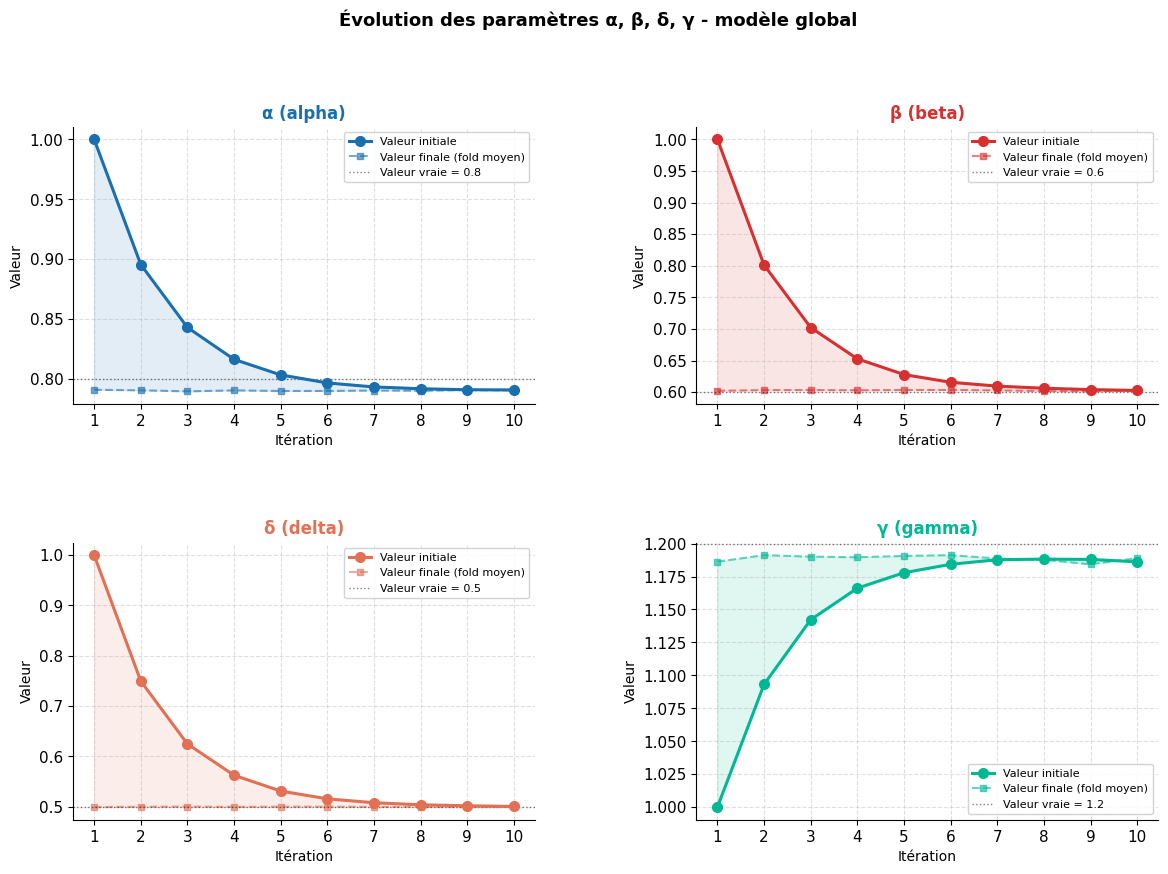

fig1_parametres.png


In [69]:
iters = np.arange(1, N_ITERATIONS + 1)

fig = plt.figure(figsize=(14, 9), facecolor='white')
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.50, wspace=0.35)

for idx in range(4):
    ax = fig.add_subplot(gs[idx // 2, idx % 2])
    c  = PARAM_COLORS[idx]
    y_init  = history['init'][:, idx]
    y_final = history['final'][:, idx]

    ax.fill_between(iters, y_init, y_final, alpha=0.12, color=c)
    ax.plot(iters, y_init,  'o-',  color=c, lw=2.2, ms=7,   label='Valeur initiale',        zorder=3)
    ax.plot(iters, y_final, 's--', color=c, lw=1.5, ms=5, alpha=0.6,
            label='Valeur finale (fold moyen)', zorder=2)
    ax.axhline(TRUE_PARAMS[idx], color='black', lw=1.0, ls=':', alpha=0.5,
               label=f'Valeur vraie = {TRUE_PARAMS[idx]}')
    ax.set_title(PARAM_NAMES[idx], fontsize=12, fontweight='bold', color=c)
    ax.set_xlabel('Itération', fontsize=10)
    ax.set_ylabel('Valeur', fontsize=10)
    ax.set_xticks(iters)
    ax.legend(fontsize=8, framealpha=0.85)

fig.suptitle("Évolution des paramètres α, β, δ, γ - modèle global",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig1_parametres.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("fig1_parametres.png")


---
## 6. Visualisation - Évolution de la MAPE (modèle global)


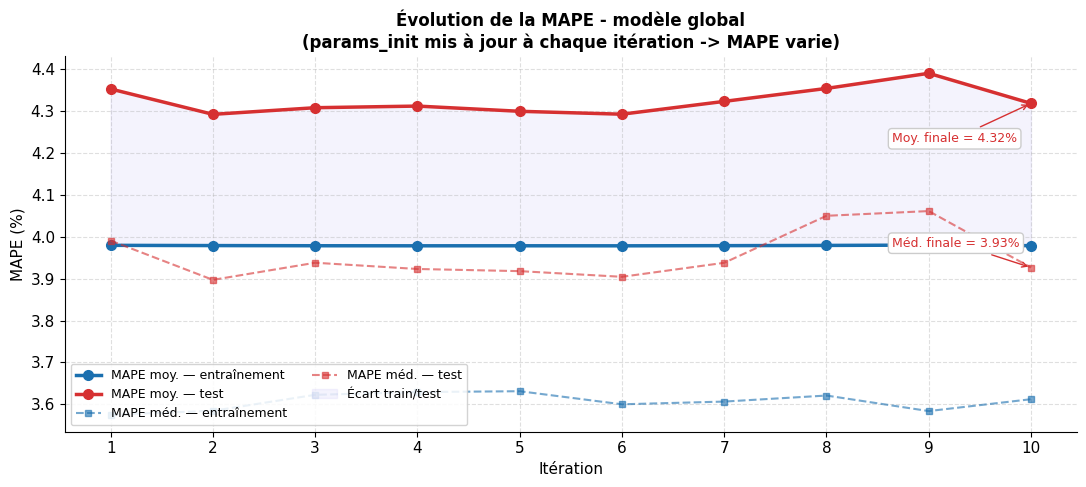

fig2_mape_evolution.png


In [70]:
fig, ax = plt.subplots(figsize=(11, 5), facecolor='white')

ax.plot(iters, history['mape_train'],     'o-',  color=COLORS['blue'], lw=2.5, ms=7,
        label='MAPE moy. — entraînement')
ax.plot(iters, history['mape_test'],      'o-',  color=COLORS['neg'],  lw=2.5, ms=7,
        label='MAPE moy. — test')
ax.plot(iters, history['mape_med_train'], 's--', color=COLORS['blue'], lw=1.5, ms=5, alpha=0.6,
        label='MAPE méd. — entraînement')
ax.plot(iters, history['mape_med_test'],  's--', color=COLORS['neg'],  lw=1.5, ms=5, alpha=0.6,
        label='MAPE méd. — test')
ax.fill_between(iters, history['mape_train'], history['mape_test'],
                alpha=0.07, color='#6c5ce7', label='Écart train/test')

ax.set_title("Évolution de la MAPE - modèle global\n"
             "(params_init mis à jour à chaque itération -> MAPE varie)",
             fontsize=12, fontweight='bold')
ax.set_xlabel('Itération', fontsize=11)
ax.set_ylabel('MAPE (%)', fontsize=11)
ax.set_xticks(iters)
ax.legend(fontsize=9, framealpha=0.85, ncol=2)

ax.annotate(f"Moy. finale = {history['mape_test'][-1]:.2f}%",
            xy=(iters[-1], history['mape_test'][-1]),
            xytext=(-100, -28), textcoords='offset points', fontsize=9, color=COLORS['neg'],
            arrowprops=dict(arrowstyle='->', color=COLORS['neg'], lw=1.0),
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#cccccc'))
ax.annotate(f"Méd. finale = {history['mape_med_test'][-1]:.2f}%",
            xy=(iters[-1], history['mape_med_test'][-1]),
            xytext=(-100, 15), textcoords='offset points', fontsize=9, color=COLORS['neg'],
            arrowprops=dict(arrowstyle='->', color=COLORS['neg'], lw=1.0),
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#cccccc'))

plt.tight_layout()
plt.savefig('fig2_mape_evolution.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("fig2_mape_evolution.png")


---
## 7. Visualisation - Distribution de la MAPE par événement


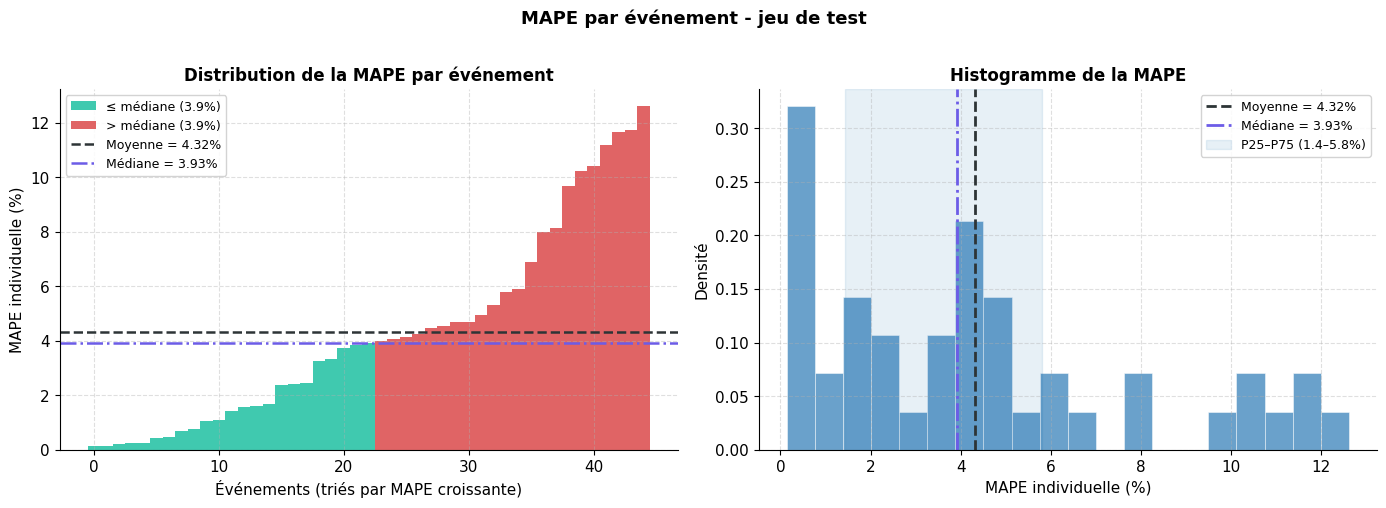

fig3_mape_distribution.png  |  Moyenne=4.32%  Médiane=3.93%


In [71]:
mape_indiv = mape_per_event(best, D_te, F_te, R_te, P_te, G_te)
mape_sorted = np.sort(mape_indiv)
mape_mean   = np.mean(mape_indiv)
mape_med    = np.median(mape_indiv)
p25, p75    = np.percentile(mape_indiv, [25, 75])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor='white')

# Barplot trié
ax = axes[0]
bar_colors = [COLORS['pos'] if v <= mape_med else COLORS['neg'] for v in mape_sorted]
ax.bar(np.arange(len(mape_sorted)), mape_sorted, color=bar_colors, alpha=0.75, width=1.0)
ax.axhline(mape_mean, color='#2d3436', lw=1.8, ls='--')
ax.axhline(mape_med,  color='#6c5ce7', lw=1.8, ls='-.')
ax.set_xlabel('Événements (triés par MAPE croissante)', fontsize=11)
ax.set_ylabel('MAPE individuelle (%)', fontsize=11)
ax.set_title('Distribution de la MAPE par événement', fontsize=12, fontweight='bold')
ax.legend(handles=[
    Patch(fc=COLORS['pos'], alpha=0.75, label=f'≤ médiane ({mape_med:.1f}%)'),
    Patch(fc=COLORS['neg'], alpha=0.75, label=f'> médiane ({mape_med:.1f}%)'),
    plt.Line2D([0],[0], color='#2d3436', lw=1.8, ls='--', label=f'Moyenne = {mape_mean:.2f}%'),
    plt.Line2D([0],[0], color='#6c5ce7', lw=1.8, ls='-.', label=f'Médiane = {mape_med:.2f}%'),
], fontsize=9, framealpha=0.85)

# Histogramme
ax2 = axes[1]
ax2.hist(mape_indiv, bins=20, color=COLORS['blue'], alpha=0.65,
         edgecolor='white', linewidth=0.5, density=True)
ax2.axvline(mape_mean, color='#2d3436', lw=2.0, ls='--', label=f'Moyenne = {mape_mean:.2f}%')
ax2.axvline(mape_med,  color='#6c5ce7', lw=2.0, ls='-.', label=f'Médiane = {mape_med:.2f}%')
ax2.axvspan(p25, p75, alpha=0.10, color=COLORS['blue'], label=f'P25–P75 ({p25:.1f}–{p75:.1f}%)')
ax2.set_xlabel('MAPE individuelle (%)', fontsize=11)
ax2.set_ylabel('Densité', fontsize=11)
ax2.set_title('Histogramme de la MAPE', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9, framealpha=0.85)

fig.suptitle("MAPE par événement - jeu de test", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig3_mape_distribution.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f"fig3_mape_distribution.png  |  Moyenne={mape_mean:.2f}%  Médiane={mape_med:.2f}%")


---
## 8. Visualisation - Comparaison des gravités (DB vs modèle)

**Panneau gauche** : scatter $G^{\text{db}}$ vs $G_\theta$ - on cherche à être
proche de $y=x$ **et** légèrement au-dessus (sur-estimation conservatrice).  
**Panneau droit** : résidus - une majorité de barres vertes (sur-estimations) est préférable.


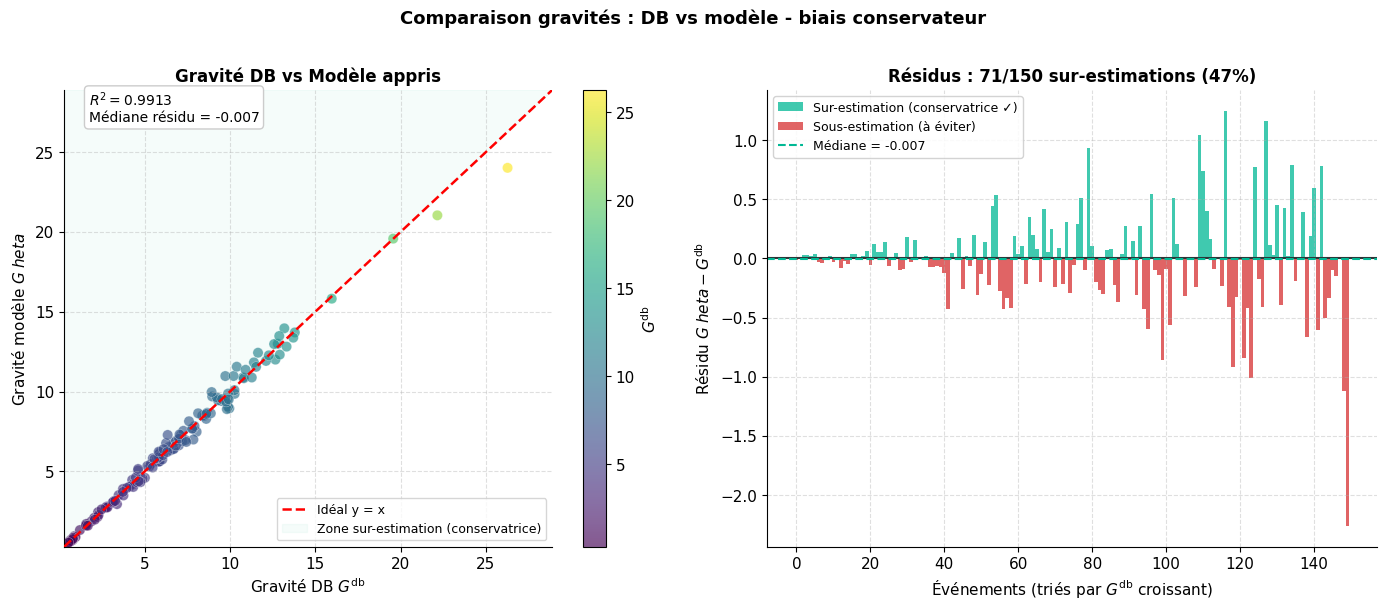

fig4_gravites.png - R²=0.9913  Médiane résidu=-0.007
Sur-estimations : 71/150 (47%)


In [72]:
G_pred = gravity(D, F, R, P, *best)
resid  = G_pred - G_db
ss_res = np.sum(resid**2)
ss_tot = np.sum((G_db - G_db.mean())**2)
r2 = 1 - ss_res / ss_tot
med_resid = np.median(resid)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), facecolor='white')

# Scatter
ax = axes[0]
sc = ax.scatter(G_db, G_pred, c=G_db, cmap='viridis',
                alpha=0.65, edgecolors='white', linewidths=0.3, s=55)
lims = [min(G_db.min(), G_pred.min()) * 0.9,
        max(G_db.max(), G_pred.max()) * 1.1]
ax.plot(lims, lims, 'r--', lw=1.8, label='Idéal y = x', zorder=3)
# Zone de sur-estimation (au-dessus de y=x)
ax.fill_between(lims, lims, [lims[1]]*2, alpha=0.04, color=COLORS['pos'],
                label='Zone sur-estimation (conservatrice)')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Gravité DB $G^{\mathrm{db}}$', fontsize=11)
ax.set_ylabel('Gravité modèle $G_\theta$', fontsize=11)
ax.set_title('Gravité DB vs Modèle appris', fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
fig.colorbar(sc, ax=ax, label='$G^{\mathrm{db}}$')
ax.text(0.05, 0.93,
        f'$R^2={r2:.4f}$\nMédiane résidu = {med_resid:+.3f}',
        transform=ax.transAxes, fontsize=10,
        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#cccccc'))

# Résidus
ax2    = axes[1]
order  = np.argsort(G_db)
rcolor = [COLORS['pos'] if r >= 0 else COLORS['neg'] for r in resid[order]]
ax2.bar(np.arange(len(resid)), resid[order], color=rcolor, alpha=0.75, width=1.0)
ax2.axhline(0,         color='#2d3436', lw=1.5)
ax2.axhline(med_resid, color=COLORS['gamma'], lw=1.5, ls='--',
            label=f'Médiane résidu = {med_resid:+.3f}')
n_over = (resid > 0).sum()
ax2.set_xlabel('Événements (triés par $G^{\mathrm{db}}$ croissant)', fontsize=11)
ax2.set_ylabel('Résidu $G_\theta - G^{\mathrm{db}}$', fontsize=11)
ax2.set_title(f'Résidus : {n_over}/{len(resid)} sur-estimations ({n_over/len(resid)*100:.0f}%)',
              fontsize=12, fontweight='bold')
ax2.legend(handles=[
    Patch(fc=COLORS['pos'], alpha=0.75, label='Sur-estimation (conservatrice ✓)'),
    Patch(fc=COLORS['neg'], alpha=0.75, label='Sous-estimation (à éviter)'),
    plt.Line2D([0],[0], color=COLORS['gamma'], lw=1.5, ls='--',
               label=f'Médiane = {med_resid:+.3f}'),
], fontsize=9, framealpha=0.85)

fig.suptitle("Comparaison gravités : DB vs modèle - biais conservateur",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig4_gravites.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f"fig4_gravites.png - R²={r2:.4f}  Médiane résidu={med_resid:+.3f}")
print(f"Sur-estimations : {n_over}/{len(resid)} ({n_over/len(resid)*100:.0f}%)")


---
## 9. Apprentissage par clusters

Pour chaque cluster $k \in \{1, 2, 3\}$, on entraîne un jeu de paramètres
$(\alpha_k, \beta_k, \delta_k, \gamma_k)$ indépendant en minimisant la MAPE
sur les événements du cluster.

L'hypothèse est que des familles d'événements structurellement différentes
obéissent à des lois de gravité différentes.


In [73]:
def learn_cluster_params(D, F, R, P, G_db, cluster_labels,
                         n_clusters=3, n_iter=8, n_splits=4):
    """
    Entraîne des paramètres spécifiques pour chaque cluster.

    Retourne
    --------
    cluster_results : list de dict, un par cluster, avec
        'params'    — meilleurs paramètres appris
        'history'   — historique MAPE (n_iter,)
        'mape_test' — MAPE sur les événements du cluster (leave-some-out)
        'n_events'  — taille du cluster
    """
    
    results = []
    for k in range(n_clusters):
        mask = cluster_labels == k
        Dk, Fk, Rk, Pk, Gk = D[mask], F[mask], R[mask], P[mask], G_db[mask]
        n_k = mask.sum()

        params_init = np.array([1.0, 1.0, 1.0, 1.0])
        hist_mape   = []

        # K-Fold adapté à la taille du cluster
        n_sp = min(n_splits, max(2, n_k // 5))
        kf   = KFold(n_splits=n_sp, shuffle=True, random_state=k)

        for it in range(n_iter):
            fold_finals, fold_mapes = [], []
            for f_tr, f_te in kf.split(Dk):
                p = optimize_fold(params_init, Dk[f_tr], Fk[f_tr], Rk[f_tr],
                                  Pk[f_tr], Gk[f_tr])
                fold_finals.append(p)
                fold_mapes.append(mean_mape(p, Dk[f_te], Fk[f_te], Rk[f_te],
                                            Pk[f_te], Gk[f_te]))

            mf = np.mean(fold_finals, axis=0)
            hist_mape.append(np.mean(fold_mapes))
            params_init = 0.5 * params_init + 0.5 * mf

        best_k = mf
        mape_k = mean_mape(best_k, Dk, Fk, Rk, Pk, Gk)
        results.append({
            'params'   : best_k,
            'history'  : np.array(hist_mape),
            'mape_test': mape_k,
            'n_events' : int(n_k),
        })
        print(f"  Cluster {k+1} ({n_k} evt) | "
              f"α={best_k[0]:.4f} β={best_k[1]:.4f} δ={best_k[2]:.4f} γ={best_k[3]:.4f} | "
              f"MAPE={mape_k:.2f}%")
    return results


print("=== Apprentissage par clusters ===\n")
CLUSTER_RESULTS = learn_cluster_params(
    D_tr, F_tr, R_tr, P_tr, G_tr,
    CLUSTER_LABELS[tr],
    n_clusters=N_CLUSTERS, n_iter=8, n_splits=4,
)

# Gravité prédite par le modèle par cluster
G_pred_cluster = np.zeros(N_EVENTS)
for k in range(N_CLUSTERS):
    mask = CLUSTER_LABELS == k
    G_pred_cluster[mask] = gravity(
        D[mask], F[mask], R[mask], P[mask], *CLUSTER_RESULTS[k]['params']
    )

mape_cluster_global = mean_mape(
    # dummy — on calcule manuellement
    [1,1,1,1], D, D, D, D, D   # placeholder, on utilise G_pred_cluster directement
)
mape_cluster_global = float(np.mean(
    np.abs(G_pred_cluster - G_db) / (np.abs(G_db) + 1e-9) * 100
))
print(f"\nMAPE globale avec paramètres par cluster : {mape_cluster_global:.2f}%")
print(f"MAPE globale avec paramètres uniques : {mean_mape(best, D_te, F_te, R_te, P_te, G_te):.2f}%")


=== Apprentissage par clusters ===

  Cluster 1 (29 evt) | α=0.7834 β=0.5608 δ=0.5347 γ=1.1966 | MAPE=3.85%
  Cluster 2 (41 evt) | α=0.7883 β=0.6098 δ=0.4990 γ=1.1885 | MAPE=4.19%
  Cluster 3 (35 evt) | α=0.8157 β=0.6052 δ=0.4936 γ=1.1711 | MAPE=3.35%

MAPE globale avec paramètres par cluster : 4.10%
MAPE globale avec paramètres uniques : 4.32%


---
## 10. Visualisation - Paramètres appris par cluster

**Panneau supérieur** : convergence de la MAPE au cours de l'entraînement pour
chaque cluster.

**Panneau inférieur** : comparaison des 4 paramètres appris par cluster vs modèle
global vs valeurs vraies.


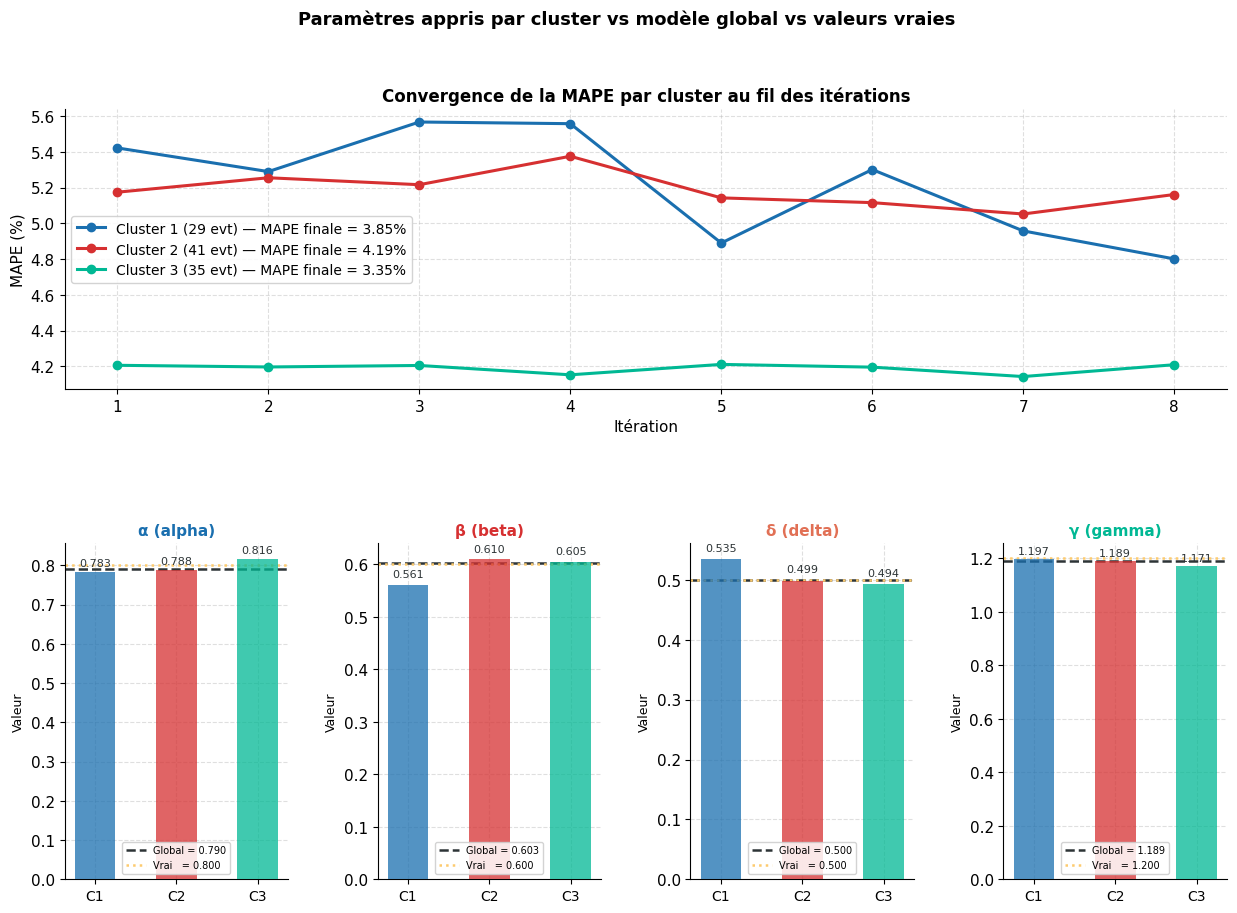

fig5_cluster_params.png


In [74]:
iters_cl    = np.arange(1, 9)
param_labels = ['α (alpha)', 'β (beta)', 'δ (delta)', 'γ (gamma)']

fig = plt.figure(figsize=(15, 10), facecolor='white')
# Ligne 1 : MAPE convergence (pleine largeur)
# Ligne 2 : 4 sous-graphes paramètres
gs_outer = gridspec.GridSpec(2, 1, figure=fig, hspace=0.50, height_ratios=[1, 1.2])

# Ligne 1 : MAPE par cluster
ax_mape = fig.add_subplot(gs_outer[0])
for k, res in enumerate(CLUSTER_RESULTS):
    ax_mape.plot(iters_cl, res['history'],
                 'o-', color=COLORS['cluster'][k], lw=2.2, ms=6,
                 label=f"Cluster {k+1} ({res['n_events']} evt) — MAPE finale = {res['mape_test']:.2f}%")
ax_mape.set_title("Convergence de la MAPE par cluster au fil des itérations",
                  fontsize=12, fontweight='bold')
ax_mape.set_xlabel('Itération', fontsize=11)
ax_mape.set_ylabel('MAPE (%)', fontsize=11)
ax_mape.set_xticks(iters_cl)
ax_mape.legend(fontsize=10, framealpha=0.85)

# Ligne 2 : 4 sous-graphes paramètres
gs_params = gridspec.GridSpecFromSubplotSpec(1, 4, subplot_spec=gs_outer[1], wspace=0.40)
bar_x      = np.arange(N_CLUSTERS)
bar_labels = [f'C{k+1}' for k in range(N_CLUSTERS)]

for pi in range(4):
    ax = fig.add_subplot(gs_params[pi])
    ax.set_facecolor('white')

    vals_clusters = [CLUSTER_RESULTS[k]['params'][pi] for k in range(N_CLUSTERS)]
    val_global    = best[pi]
    val_true      = TRUE_PARAMS[pi]

    bars = ax.bar(bar_x, vals_clusters,
                  color=COLORS['cluster'], alpha=0.75, width=0.5, zorder=3)
    ax.axhline(val_global, color='#2d3436', lw=1.8, ls='--',
               label=f'Global = {val_global:.3f}')
    ax.axhline(val_true,   color='#fdcb6e', lw=1.8, ls=':',
               label=f'Vrai   = {val_true:.3f}')

    ax.set_xticks(bar_x)
    ax.set_xticklabels(bar_labels, fontsize=10)
    ax.set_title(param_labels[pi], fontsize=11, fontweight='bold',
                 color=PARAM_COLORS[pi])
    ax.set_ylabel('Valeur', fontsize=9)
    ax.legend(fontsize=7, framealpha=0.85)
    ax.grid(True, linestyle='--', alpha=0.4)

    for b, v in zip(bars, vals_clusters):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                f'{v:.3f}', ha='center', va='bottom', fontsize=8, color='#2d3436')

fig.suptitle("Paramètres appris par cluster vs modèle global vs valeurs vraies",
             fontsize=13, fontweight='bold')
plt.savefig('fig5_cluster_params.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("fig5_cluster_params.png")


---
## 11. Poids statiques, normalisation L¹ et état de santé

**Référence article :** §6.3–6.4 - *Poids statiques et normalisation L¹*

Conformément au modèle final (§6.4, Déf. 6.3), les poids $\omega_i$ sont **statiques** :
ils ne varient pas dans le temps. L'extinction temporelle est entièrement pilotée
par {\text{eff}}(t)$ dans l'opérateur $\Gamma$ (§3.3).

- **$\omega_i > 0* : événement favoris (contribue positivement à $\zeta$)
- **$\omega_i < 0* : événement défavorable (contribue négativement à $\zeta$)
- **$|\omega_i|* : intensité de l'influence, indépendamment du signe

**Propriétés de la normalisation L¹ (Prop. 6.2) :**
1. *Invariance à l'échelle* : multiplier tous $\omega_i$ par  > 0$ ne change pas $\zeta$
2. *Stabilité* : ajouter un événement neutre ($\omega = 0$) ne modifie pas (t)$
3. *Borne de contrôle* : $|S(t)| \leq \max_i |G^e_i(t)|$

On trace :
1. La **décomposition de N_actif(t)** en événements positifs et négatifs
2. L'**état de santé $\zeta(t)* calculé avec poids statiques et gravité résiduelle {\text{eff}}(t)$


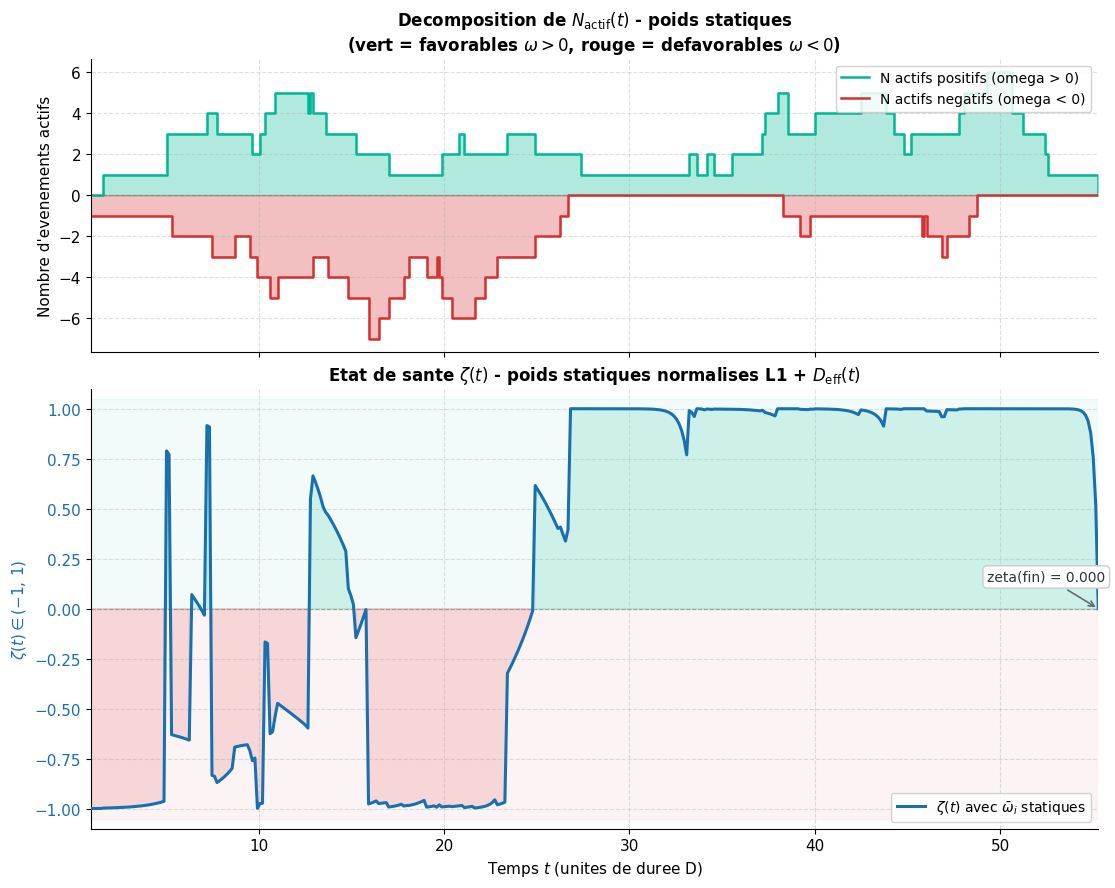

fig6_poids_statiques.png
zeta_min=-0.999  zeta_max=1.000  zeta_fin=0.000


In [75]:
def compute_health_static(
        D_test, F_test, R_test, P_test, t_start,
        omega_static, params,
        W_matrix=None, t_resolution=400):
    """
    Calcule zeta(t) avec poids statiques normalises L1 + gravite residuelle Deff(t).

    Conformement au modele final (§6.3-6.4 + §3.3) :
    - Les poids w_i sont statiques (pas de decroissance temporelle).
    - L'extinction temporelle est geree par Deff(t) = max(D-(t-t0), 0) dans Gamma.
    - Normalisation L1 : w_bar_i = w_i / sum(|w_j|) (Def. 6.4)

    Retourne
    --------
    t_grid  : np.ndarray
    zeta_t  : np.ndarray -- zeta a chaque t
    n_actif : np.ndarray -- nombre d'evenements actifs
    n_pos   : np.ndarray -- evenements a omega > 0
    n_neg   : np.ndarray -- evenements a omega < 0
    """
    
    alpha, beta, delta, gamma = params
    t_end  = t_start + D_test
    t_min  = t_start.min()
    t_max  = t_end.max()
    t_grid = np.linspace(t_min, t_max, t_resolution)

    zeta_t  = np.zeros(t_resolution)
    n_actif = np.zeros(t_resolution, dtype=int)
    n_pos   = np.zeros(t_resolution, dtype=int)
    n_neg   = np.zeros(t_resolution, dtype=int)

    for k, t in enumerate(t_grid):
        mask = (t_start <= t) & (t < t_end)
        n_actif[k] = int(mask.sum())
        if n_actif[k] == 0:
            continue

        # Poids statiques (fixes dans le temps)
        w_k   = omega_static[mask]
        n_pos[k] = int((w_k > 0).sum())
        n_neg[k] = int((w_k < 0).sum())

        # Gravite residuelle Deff(t) -- extinction naturelle
        Gk = gravity_residual(
            D_test[mask], F_test[mask], R_test[mask], P_test[mask],
            alpha, beta, delta, gamma, t, t_start[mask]
        )

        # Gravite effective via W(t)
        if W_matrix is not None:
            idx_a = np.where(mask)[0]
            Wk    = W_matrix[np.ix_(idx_a, idx_a)]
            G_eff = (np.eye(n_actif[k]) + Wk) @ Gk
        else:
            G_eff = Gk.copy()

        # Normalisation L1 (Def. 6.4)
        norm = np.sum(np.abs(w_k))
        if norm < 1e-12:
            zeta_t[k] = 0.0
            continue
        S = np.dot(w_k / norm, G_eff)
        zeta_t[k] = float(np.tanh(S))

    return t_grid, zeta_t, n_actif, n_pos, n_neg



# Matrice d'interaction W(t)
rng_w  = np.random.default_rng(RANDOM_SEED + 1)
N_te   = len(D_te)
W_test = rng_w.uniform(-0.05, 0.10, (N_te, N_te))
np.fill_diagonal(W_test, 0)

# Poids statiques issus de OMEGA0_te
omega_static_te = OMEGA0_te.copy()   # fixes, pas de decroissance

t_grid, zeta_t, n_actif, n_pos, n_neg = compute_health_static(
    D_te, F_te, R_te, P_te, T_te,
    omega_static_te, best,
    W_matrix=W_test, t_resolution=400,
)

# Graphique : 2 panneaux
fig, axes = plt.subplots(2, 1, figsize=(13, 10),
                          sharex=True, facecolor='white',
                          gridspec_kw={'height_ratios': [1, 1.5], 'hspace': 0.10})

# Panneau 1 : decomposition N_actif(t) positifs / negatifs
ax_n = axes[0]
ax_n.fill_between(t_grid,  n_pos, step='post', alpha=0.30, color=COLORS['pos'])
ax_n.fill_between(t_grid, -n_neg, step='post', alpha=0.30, color=COLORS['neg'])
ax_n.step(t_grid,  n_pos, where='post', color=COLORS['pos'], lw=1.8,
          label='N actifs positifs (omega > 0)')
ax_n.step(t_grid, -n_neg, where='post', color=COLORS['neg'], lw=1.8,
          label='N actifs negatifs (omega < 0)')
ax_n.axhline(0, color=COLORS['gray'], lw=0.8, ls='--', alpha=0.5)
ax_n.set_ylabel("Nombre d'evenements actifs", fontsize=11)
ax_n.set_title(
    r"Decomposition de $N_{\mathrm{actif}}(t)$ - poids statiques" + "\n"
    r"(vert = favorables $\omega>0$, rouge = defavorables $\omega<0$)",
    fontsize=12, fontweight='bold')
ax_n.legend(fontsize=10, loc='upper right', framealpha=0.85)

# Panneau 2 : zeta(t) avec poids statiques
ax_z = axes[1]
ax_z.axhspan( 0,  1.05, alpha=0.05, color=COLORS['pos'])
ax_z.axhspan(-1.05, 0,  alpha=0.05, color=COLORS['neg'])
ax_z.axhline(0, color=COLORS['gray'], lw=0.8, ls='--', alpha=0.6, zorder=1)

ax_z.plot(t_grid, zeta_t, color=COLORS['blue'], lw=2.2, zorder=3,
          label=r'$\zeta(t)$ avec $\bar{\omega}_i$ statiques')
ax_z.fill_between(t_grid, zeta_t, 0,
                  where=(zeta_t >= 0), alpha=0.15, color=COLORS['pos'])
ax_z.fill_between(t_grid, zeta_t, 0,
                  where=(zeta_t <  0), alpha=0.15, color=COLORS['neg'])

zf = zeta_t[-1]
ax_z.annotate(f'zeta(fin) = {zf:.3f}',
              xy=(t_grid[-1], zf),
              xytext=(-80, 20 if zf < 0.5 else -30),
              textcoords='offset points', fontsize=10, color='#2d3436',
              arrowprops=dict(arrowstyle='->', color=COLORS['gray'], lw=1.2),
              bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#cccccc'))

ax_z.set_ylim(-1.1, 1.1)
ax_z.set_xlim(t_grid[0], t_grid[-1])
ax_z.set_xlabel('Temps $t$ (unites de duree D)', fontsize=11)
ax_z.set_ylabel(r'$\zeta(t) \in (-1,\,1)$', fontsize=11, color=COLORS['blue'])
ax_z.tick_params(axis='y', labelcolor=COLORS['blue'])
ax_z.set_title(
    r'Etat de sante $\zeta(t)$ - poids statiques normalises L1 + $D_{\mathrm{eff}}(t)$',
    fontsize=12, fontweight='bold')
ax_z.legend(fontsize=10, loc='lower right', framealpha=0.85)

plt.savefig('fig6_poids_statiques.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("fig6_poids_statiques.png")
print(f"zeta_min={zeta_t.min():.3f}  zeta_max={zeta_t.max():.3f}  zeta_fin={zf:.3f}")


---
## 12. Visualisation - ζ(t) et N_actif(t) avec coloration pos/neg

**Référence article :** §6.8 (Fig. 11) - *Évolution conjointe de ζ(t) et du nombre d'événements actifs*

Le sous-graphe $N_{\text{actif}}(t)$ est **bicolore** :
- **Vert** : proportion d'événements actifs à poids **positif** (favorables, $\omega > 0$)
- **Rouge** : proportion d'événements actifs à poids **négatif** (défavorables, $\omega < 0$)

Les poids étant **statiques**, la coloration est fixe dans le temps pour chaque événement.
La cohérence qualitative (majorité négatifs ↔ ζ < 0, majorité positifs ↔ ζ > 0) valide
le comportement attendu du modèle.


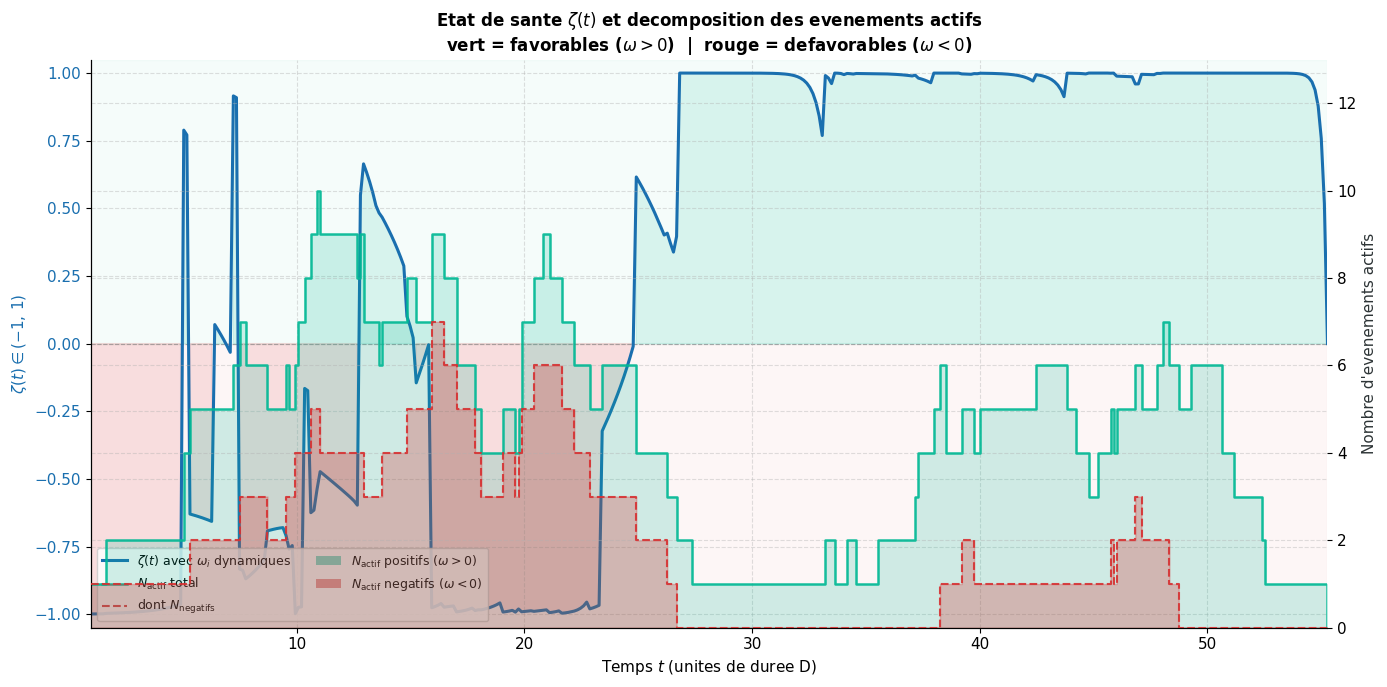

fig7_sante_temporelle_color.png
N_actif max = 10 - zeta min/max = -0.999/1.000


In [76]:
def compute_health_bicolor(
        D_test, F_test, R_test, P_test, t_start,
        omega_static, params,
        W_matrix=None, t_resolution=400):
    """
    Calcule zeta(t) et la decomposition pos/neg de N_actif(t).
    Poids statiques + gravite residuelle Deff(t) (§6.3 + §3.3).

    Retourne : t_grid, zeta_t, n_actif, n_pos, n_neg
    """
    
    alpha, beta, delta, gamma = params
    t_end  = t_start + D_test
    t_grid = np.linspace(t_start.min(), t_end.max(), t_resolution)

    zeta_t  = np.zeros(t_resolution)
    n_actif = np.zeros(t_resolution, dtype=int)
    n_pos   = np.zeros(t_resolution, dtype=int)
    n_neg   = np.zeros(t_resolution, dtype=int)

    for k, t in enumerate(t_grid):
        mask = (t_start <= t) & (t < t_end)
        n_actif[k] = int(mask.sum())
        if n_actif[k] == 0:
            continue

        w_k = omega_static[mask]
        n_pos[k] = int((w_k > 0).sum())
        n_neg[k] = int((w_k < 0).sum())

        Gk = gravity_residual(
            D_test[mask], F_test[mask], R_test[mask], P_test[mask],
            alpha, beta, delta, gamma, t, t_start[mask]
        )
        if W_matrix is not None:
            idx_a = np.where(mask)[0]
            Wk    = W_matrix[np.ix_(idx_a, idx_a)]
            G_eff = (np.eye(n_actif[k]) + Wk) @ Gk
        else:
            G_eff = Gk.copy()

        norm = np.sum(np.abs(w_k))
        if norm < 1e-12:
            continue
        zeta_t[k] = float(np.tanh(np.dot(w_k / norm, G_eff)))

    return t_grid, zeta_t, n_actif, n_pos, n_neg


t_grid2, zeta_t2, n_actif2, n_pos2, n_neg2 = compute_health_bicolor(
    D_te, F_te, R_te, P_te, T_te,
    omega_static_te, best,
    W_matrix=W_test, t_resolution=400,
)

# Graphique double-axe
fig, ax1 = plt.subplots(figsize=(14, 7), facecolor='white')
ax2 = ax1.twinx()

# Axe droit : N_actif bicolore (vert total, rouge negatifs)
ax2.fill_between(t_grid2, n_actif2, step='post', alpha=0.18, color=COLORS['pos'])
ax2.step(t_grid2, n_actif2, where='post', color=COLORS['pos'], lw=1.8, alpha=0.9,
         label=r'$N_{\mathrm{actif}}$ total', zorder=2)
ax2.fill_between(t_grid2, n_neg2, step='post', alpha=0.28, color=COLORS['neg'])
ax2.step(t_grid2, n_neg2, where='post', color=COLORS['neg'], lw=1.5, alpha=0.9,
         ls='--', label=r'dont $N_{\mathrm{negatifs}}$', zorder=3)

# Axe gauche : zeta(t)
ax1.axhspan( 0,  1.05, alpha=0.04, color=COLORS['pos'])
ax1.axhspan(-1.05, 0,  alpha=0.04, color=COLORS['neg'])
ax1.axhline(0, color=COLORS['gray'], lw=0.8, ls='--', alpha=0.6, zorder=1)
ax1.plot(t_grid2, zeta_t2, color=COLORS['blue'], lw=2.2, zorder=4,
         label=r'$\zeta(t)$ avec $\omega_i$ dynamiques')
ax1.fill_between(t_grid2, zeta_t2, 0,
                 where=(zeta_t2 >= 0), alpha=0.12, color=COLORS['pos'])
ax1.fill_between(t_grid2, zeta_t2, 0,
                 where=(zeta_t2 <  0), alpha=0.12, color=COLORS['neg'])

ax1.set_ylim(-1.05, 1.05)
ax1.set_xlim(t_grid2[0], t_grid2[-1])
ax1.set_xlabel('Temps $t$ (unites de duree D)', fontsize=11)
ax1.set_ylabel(r'$\zeta(t) \in (-1,\,1)$', fontsize=11, color=COLORS['blue'])
ax1.tick_params(axis='y', labelcolor=COLORS['blue'])
ax2.set_ylabel("Nombre d'evenements actifs", fontsize=11, color='#2d3436')
ax2.set_ylim(0, n_actif2.max() * 1.30)
ax2.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))

lines1, lbl1 = ax1.get_legend_handles_labels()
lines2, lbl2 = ax2.get_legend_handles_labels()
extra = [
    Patch(fc=COLORS['pos'], alpha=0.5, label=r'$N_{\mathrm{actif}}$ positifs ($\omega > 0$)'),
    Patch(fc=COLORS['neg'], alpha=0.5, label=r'$N_{\mathrm{actif}}$ negatifs ($\omega < 0$)'),
]
ax1.legend(lines1 + lines2 + extra, lbl1 + lbl2 + [e.get_label() for e in extra],
           fontsize=9, loc='lower left', framealpha=0.85, ncol=2)

ax1.set_title(
    r"Etat de sante $\zeta(t)$ et decomposition des evenements actifs" + "\n"
    r"vert = favorables ($\omega > 0$)  |  rouge = defavorables ($\omega < 0$)",
    fontsize=12, fontweight='bold',
)

plt.tight_layout()
plt.savefig('fig7_sante_temporelle_color.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("fig7_sante_temporelle_color.png")
print(f"N_actif max = {n_actif2.max()} - zeta min/max = {zeta_t2.min():.3f}/{zeta_t2.max():.3f}")


---
## 13. Extension - Dilatation de tanh par un facteur λ

**Référence article :** §7.1 - *Ajustement de la sensibilité de tanh par dilatation*

L'opérateur standard utilise $\zeta(E(t)) = \tanh(S(t))$.
Avec dilatation (Déf. 7.1) :

$$\zeta_\lambda(E(t)) = \tanh\!\left(\frac{S(t)}{\lambda}\right), \qquad \lambda > 0$$

**Propriétés (Prop. 7.1) :**
- *Sensibilité locale* : $\zeta'_\lambda(0) = 1/\lambda$ - inversement proportionnelle à $\lambda$
- *Seuil de saturation* : $\zeta_\lambda \approx 0.95$ dès $|S| \geq 1.83\,\lambda$
- *Régime diffus* : $\lambda \to +\infty \Rightarrow \zeta_\lambda \to 0$ (perte d'information)

### Problème d'échelle temporelle

Quand l'environnement accumule de nombreux événements, la contribution cumulée croît artificiellement. L'article propose alors $\lambda(t) = N(t)$ (Éq. 27) :

$$\lambda(t) = N(t)$$

### Dilatation adaptative pénalisée (Déf. 7.2)

Pour éviter les plateaux locaux persistants, une pénalisation exponentielle est introduite :

$$\lambda(t) = \alpha\, N(t) \cdot e^{\beta\, |\zeta_\lambda(t^-)|}$$

- **Zone neutre** $(|\zeta_\lambda(t^-)| \approx 0)$ : $\lambda(t) \approx \alpha N(t)$
- **Saturation imminente** $(|\zeta_\lambda(t^-)| \approx 1)$ : $\lambda(t) \approx \alpha N(t)\, e^\beta$ — rend l'atteinte de $\pm 1$ exponentiellement difficile

Ce mécanisme encode précisément le **principe d'impossibilité des extrêmes absolus** (§6.3).


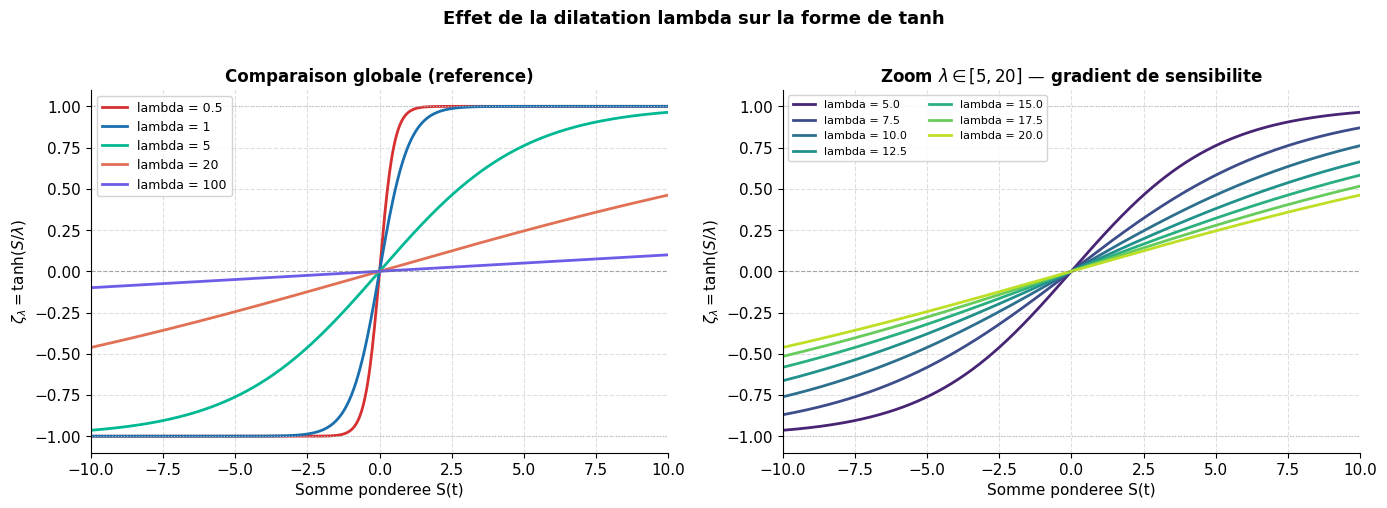

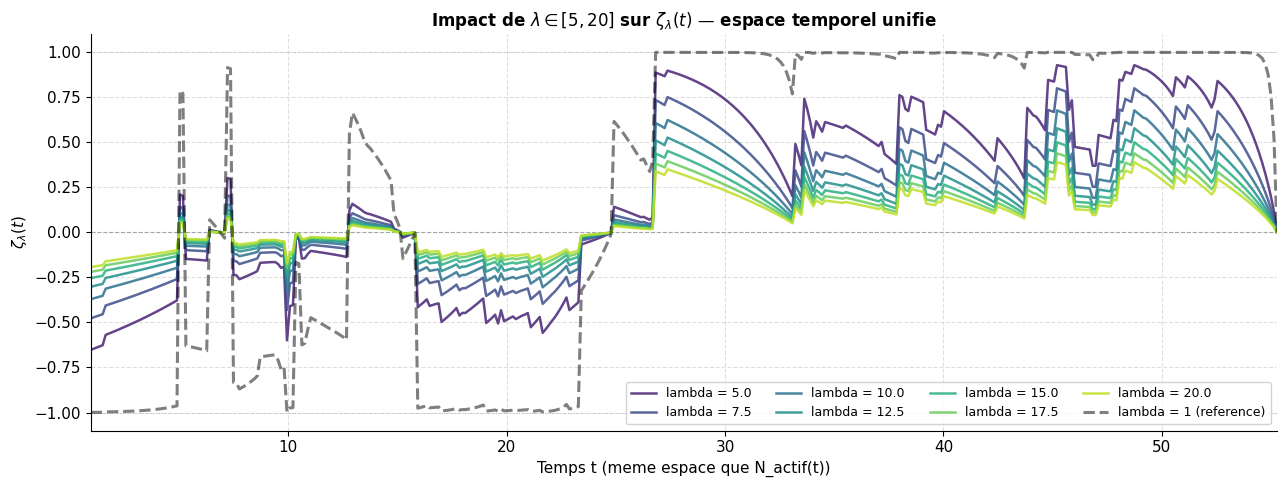

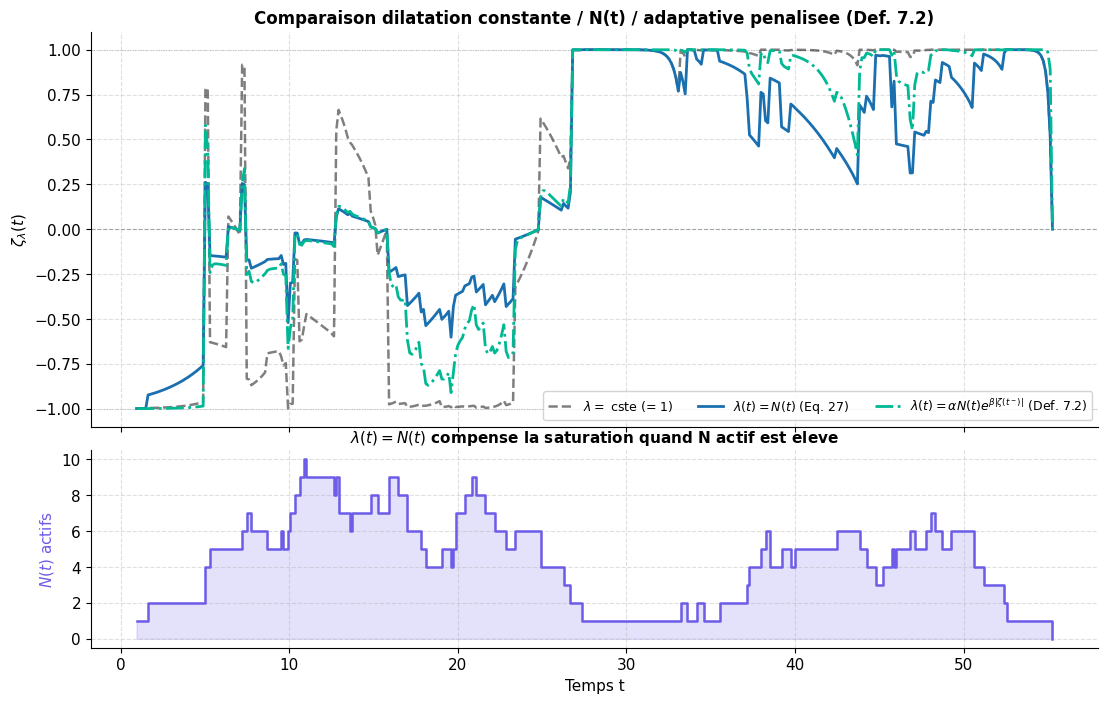

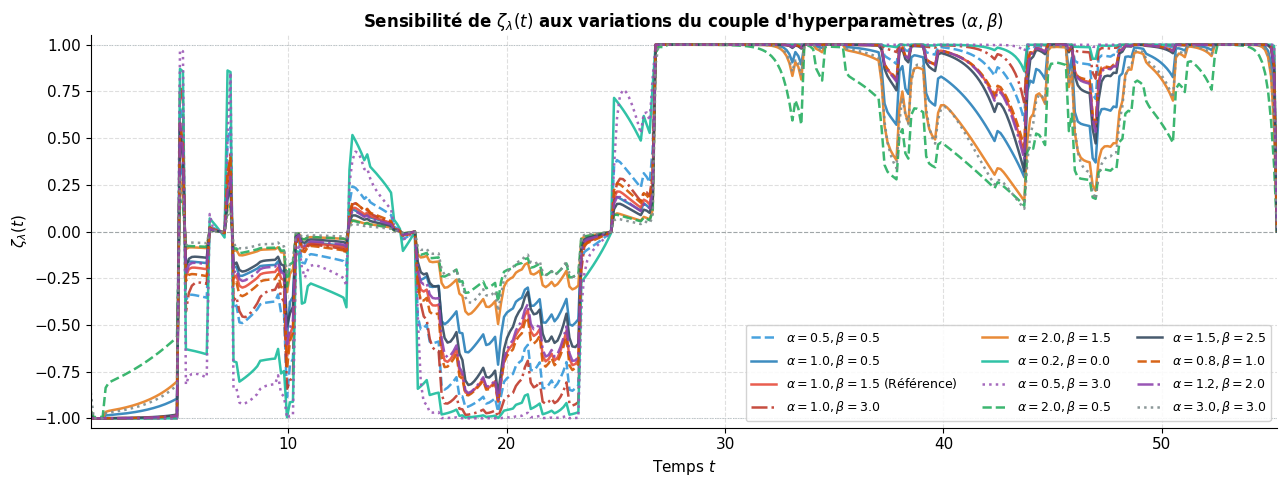

fig8a + fig8b + fig8c + fig8d

Seuils de saturation zeta=0.95 pour lambda dans [5, 20] :
  lambda |   deriv en 0 |   S pour zeta=0.95 | Interpretation
----------------------------------------------------------------------
     0.5 |        2.000 |               0.92 | Tres sensible
     1.0 |        1.000 |               1.83 | Standard
     5.0 |        0.200 |               9.16 | Filtre modere
    20.0 |        0.050 |              36.64 | Filtre fort
   100.0 |        0.010 |             183.18 | Quasi-lineaire


In [77]:
# Definition de zeta_lambda
def health_dilated(S, lam):
    """zeta_lambda(S) = tanh(S / lambda). lambda > 0."""
    return np.tanh(S / lam)


def health_dilated_adaptive(S_series, N_series, alpha_dl=1.0, beta_dl=1.5):
    """
    Dilatation adaptative penalisee (Def. 7.2 de l'article).

    lambda(t) = alpha * N(t) / (1 + beta * |zeta(t-1)|)

    Logique anti-plateau :
    - N(t) grand  → lambda grand  -> compense l'accumulation d'evenements
    - |zeta(t-1)| proche de 1 -> lambda DIMINUE → ramene zeta vers 0
      (contrairement a une penalisation exponentielle qui ferait l'inverse)

    Parameters
    ----------
    S_series  : np.ndarray - somme ponderee S(t) brute
    N_series  : np.ndarray - nombre d'evenements actifs N(t) (entiers)
    alpha_dl  : float - facteur global de calibration (default 1.0)
    beta_dl   : float - intensite de la correction anti-plateau (default 1.5)
    """
    
    n = len(S_series)
    zeta_out = np.zeros(n)
    for k in range(n):
        N_k       = max(1, int(N_series[k]))
        zeta_prev = abs(zeta_out[k-1]) if k > 0 else 0.0
        # lambda diminue quand zeta s'approche des bornes -> force le retour au centre
        lam_k = alpha_dl * N_k / (1.0 + beta_dl * zeta_prev)
        lam_k = max(lam_k, 0.1)
        zeta_out[k] = float(np.tanh(S_series[k] / lam_k))
        
    return zeta_out


# S(t) brut
def compute_S_timeline(D_test, F_test, R_test, P_test, t_start,
                       omega_static, params,
                       W_matrix=None, t_resolution=400):
    
    """Retourne t_grid et S(t) brut (avant tanh) avec poids statiques."""
    
    alpha, beta, delta, gamma = params
    t_end  = t_start + D_test
    t_grid = np.linspace(t_start.min(), t_end.max(), t_resolution)
    S_t    = np.zeros(t_resolution)
    N_t    = np.zeros(t_resolution, dtype=int)

    for k, t in enumerate(t_grid):
        mask = (t_start <= t) & (t < t_end)
        if not mask.any():
            continue
        w_k  = omega_static[mask]
        N_t[k] = int(mask.sum())
        Gk   = gravity_residual(
            D_test[mask], F_test[mask], R_test[mask], P_test[mask],
            alpha, beta, delta, gamma, t, t_start[mask]
        )
        if W_matrix is not None:
            idx_a = np.where(mask)[0]
            Wk    = W_matrix[np.ix_(idx_a, idx_a)]
            G_eff = (np.eye(mask.sum()) + Wk) @ Gk
        else:
            G_eff = Gk.copy()
        norm = np.sum(np.abs(w_k))
        if norm < 1e-12:
            continue
        S_t[k] = np.dot(w_k / norm, G_eff)

    return t_grid, S_t, N_t


t_grid_s, S_t, N_t = compute_S_timeline(
    D_te, F_te, R_te, P_te, T_te,
    omega_static_te, best,
    W_matrix=W_test, t_resolution=400,
)

# Panneau 1 : formes de tanh(S/lambda)
S_range      = np.linspace(-10, 10, 500)
lambdas_all  = [0.5, 1, 5, 20, 100]
lambdas_focus = np.linspace(5, 20, 7)
lam_cmap     = plt.cm.viridis(np.linspace(0.1, 0.9, len(lambdas_focus)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor='white')

ax = axes[0]
lam_colors_all = ['#d63031', '#1a6faf', '#00b894', '#e17055', '#6c5ce7']
for lam, col in zip(lambdas_all, lam_colors_all):
    ax.plot(S_range, health_dilated(S_range, lam), color=col, lw=2.0, label=f'lambda = {lam}')
ax.axhline(0, color=COLORS['gray'], lw=0.8, ls='--', alpha=0.5)
ax.axhline( 1, color='#b2bec3', lw=0.8, ls=':')
ax.axhline(-1, color='#b2bec3', lw=0.8, ls=':')
ax.set_xlim(-10, 10); ax.set_ylim(-1.1, 1.1)
ax.set_xlabel('Somme ponderee S(t)', fontsize=11)
ax.set_ylabel(r'$\zeta_\lambda = \tanh(S/\lambda)$', fontsize=11)
ax.set_title('Comparaison globale (reference)', fontsize=12, fontweight='bold')
ax.legend(fontsize=9, framealpha=0.85)

ax2 = axes[1]
for lam, col in zip(lambdas_focus, lam_cmap):
    ax2.plot(S_range, health_dilated(S_range, lam), color=col, lw=2.0, label=f'lambda = {lam:.1f}')
ax2.axhline(0, color=COLORS['gray'], lw=0.8, ls='--', alpha=0.5)
ax2.axhline( 1, color='#b2bec3', lw=0.8, ls=':')
ax2.axhline(-1, color='#b2bec3', lw=0.8, ls=':')
ax2.set_xlim(-10, 10); ax2.set_ylim(-1.1, 1.1)
ax2.set_xlabel('Somme ponderee S(t)', fontsize=11)
ax2.set_ylabel(r'$\zeta_\lambda = \tanh(S/\lambda)$', fontsize=11)
ax2.set_title(r'Zoom $\lambda \in [5, 20]$ — gradient de sensibilite', fontsize=12, fontweight='bold')
ax2.legend(fontsize=8, framealpha=0.85, ncol=2)

fig.suptitle("Effet de la dilatation lambda sur la forme de tanh",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig8a_dilatation_forme.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# Panneau 2 : impact de lambda sur zeta(t)
fig, ax = plt.subplots(figsize=(13, 5), facecolor='white')
ax.axhline(0, color=COLORS['gray'], lw=0.8, ls='--', alpha=0.5)
ax.axhline( 1, color='#b2bec3', lw=0.7, ls=':')
ax.axhline(-1, color='#b2bec3', lw=0.7, ls=':')

for lam, col in zip(lambdas_focus, lam_cmap):
    ax.plot(t_grid_s, health_dilated(S_t, lam), color=col, lw=1.8, alpha=0.85,
            label=f'lambda = {lam:.1f}')
ax.plot(t_grid_s, health_dilated(S_t, 1),
        color='black', lw=2.2, ls='--', alpha=0.5, label='lambda = 1 (reference)')

ax.set_ylim(-1.1, 1.1)
ax.set_xlim(t_grid_s[0], t_grid_s[-1])
ax.set_xlabel('Temps t (meme espace que N_actif(t))', fontsize=11)
ax.set_ylabel(r'$\zeta_\lambda(t)$', fontsize=11)
ax.set_title(r'Impact de $\lambda \in [5, 20]$ sur $\zeta_\lambda(t)$ — espace temporel unifie',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=9, framealpha=0.85, ncol=4)
plt.tight_layout()
plt.savefig('fig8b_dilatation_temporel.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# Panneau 3 : dilatation adaptative penalisee (Def. 7.2)
fig, axes3 = plt.subplots(2, 1, figsize=(13, 8), sharex=True, facecolor='white',
                           gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.08})

zeta_lambda_cste = health_dilated(S_t, 1.0)
zeta_lambda_N    = np.array([np.tanh(S_t[k] / max(float(N_t[k]), 1)) for k in range(len(S_t))])
zeta_lambda_adap = health_dilated_adaptive(S_t, N_t, alpha_dl=1.0, beta_dl=1.5)

ax_a = axes3[0]
ax_a.axhline(0, color=COLORS['gray'], lw=0.8, ls='--', alpha=0.5)
ax_a.axhline( 1, color='#b2bec3', lw=0.7, ls=':')
ax_a.axhline(-1, color='#b2bec3', lw=0.7, ls=':')
ax_a.plot(t_grid_s, zeta_lambda_cste, color='black', lw=1.8, ls='--', alpha=0.5, label=r'$\lambda = $ cste (= 1)')
ax_a.plot(t_grid_s, zeta_lambda_N,    color=COLORS['blue'],  lw=2.0, label=r'$\lambda(t) = N(t)$ (Eq. 27)')
ax_a.plot(t_grid_s, zeta_lambda_adap, color=COLORS['pos'],   lw=2.0, ls='-.', label=r'$\lambda(t) = \alpha N(t) e^{\beta|\zeta(t^-)|}$ (Def. 7.2)')
ax_a.set_ylim(-1.1, 1.1)
ax_a.set_ylabel(r'$\zeta_\lambda(t)$', fontsize=11)
ax_a.set_title('Comparaison dilatation constante / N(t) / adaptative penalisee (Def. 7.2)', fontsize=12, fontweight='bold')
ax_a.legend(fontsize=9, framealpha=0.85, ncol=3)

ax_b = axes3[1]
ax_b.step(t_grid_s, N_t, where='post', color=COLORS['count'], lw=1.8)
ax_b.fill_between(t_grid_s, N_t, step='post', alpha=0.18, color=COLORS['count'])
ax_b.set_xlabel('Temps t', fontsize=11)
ax_b.set_ylabel(r'$N(t)$ actifs', fontsize=11, color=COLORS['count'])
ax_b.set_title(r'$\lambda(t) = N(t)$ compense la saturation quand N actif est eleve', fontsize=11, fontweight='bold')

plt.savefig('fig8c_dilatation_adaptative.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# Panneau 4 : sensibilite aux hyperparametres (alpha, beta)
alpha_beta_grid = [
    # Bloc d'origine demandé
    (0.5, 0.5, '#3498db', '--'),  # Hyper réactif, faible pénalité
    (1.0, 0.5, '#2980b9', '-'),   # Échelle standard, faible pénalité
    (1.0, 1.5, '#e74c3c', '-'),   # RÉFÉRENCE
    (1.0, 3.0, '#c0392b', '-.'),  # Échelle standard, fort étouffement historique
    (2.0, 1.5, '#e67e22', '-'),   # Amortissement de base fort, pénalité moyenne
    
    # Extensions complémentaires pour atteindre 12 profils distincts
    (0.2, 0.0, '#1abc9c', '-'),   # Profil Extrême : Quasi pas de dilatation (proche tanh pur)
    (0.5, 3.0, '#9b59b6', ':'),   # Profil Mixte : Très nerveux puis se bloque très vite
    (2.0, 0.5, '#27ae60', '--'),  # Profil Stable : Échelle forte, pas d'effet mémoire
    (1.5, 2.5, '#34495e', '-'),   # Profil Lissé : Bon compromis de filtrage global
    (0.8, 1.0, '#d35400', '--'),  # Profil Ajusté : Légèrement plus réactif que la référence
    (1.2, 2.0, '#8e44ad', '-.'),  # Profil Conservateur : Légèrement plus amorti que la référence
    (3.0, 3.0, '#7f8c8d', ':')    # Profil Écrasé : Très forte dilatation, dynamique aplatie
]
fig, ax_sens = plt.subplots(figsize=(13, 5), facecolor='white')
ax_sens.axhline(0,  color=COLORS['gray'], lw=0.8, ls='--', alpha=0.5)
ax_sens.axhline( 1, color='#b2bec3', lw=0.7, ls=':')
ax_sens.axhline(-1, color='#b2bec3', lw=0.7, ls=':')
for a, b, col, ls in alpha_beta_grid:
    z = health_dilated_adaptive(S_t, N_t, alpha_dl=a, beta_dl=b)
    lbl = rf'$\alpha={a},\beta={b}$' + (' (Référence)' if a==1.0 and b==1.5 else '')
    ax_sens.plot(t_grid_s, z, color=col, lw=1.8, ls=ls, alpha=0.9, label=lbl)
ax_sens.set_ylim(-1.05, 1.05)
ax_sens.set_xlim(t_grid_s[0], t_grid_s[-1])
ax_sens.set_xlabel('Temps $t$', fontsize=11)
ax_sens.set_ylabel(r'$\zeta_\lambda(t)$', fontsize=11)
ax_sens.set_title(
    r"Sensibilité de $\zeta_\lambda(t)$ aux variations du couple d'hyperparamètres $(\alpha, \beta)$",
    fontsize=12, fontweight='bold')
ax_sens.legend(fontsize=9, framealpha=0.85, ncol=3)
plt.tight_layout()
plt.savefig('fig8d_sensibilite_alpha_beta.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("fig8a + fig8b + fig8c + fig8d")

# Tableau des seuils
print("\nSeuils de saturation zeta=0.95 pour lambda dans [5, 20] :")
print(f"{'lambda':>8} | {'deriv en 0':>12} | {'S pour zeta=0.95':>18} | Interpretation")
print("-" * 70)
interp = {0.5: "Tres sensible", 1: "Standard", 5: "Filtre modere", 20: "Filtre fort", 100: "Quasi-lineaire"}
for lam in [0.5, 1, 5, 20, 100]:
    print(f"{lam:>8.1f} | {1/lam:>12.3f} | {lam*float(__import__('numpy').arctanh(0.95)):>18.2f} | {interp.get(lam,'')}")


---
## 7.2 Lissage temporal - Spline cubique sur discontinuités

**Référence article :** §7.2 - *Lissage temporel par interpolation*

Les améliorations précédentes (dilatation λ, poids statiques) sont maintenant 
**appliquées directement à ζ(t)** pour générer un signal lissé et robuste.

Cette section :
1. Applique dilatation λ(t) = N(t) au signal brut
2. Détecte **tous** les points de discontinuité
3. Lisse via spline cubique aux nœuds adaptatifs
4. **Met à jour ζ_final** globalement pour les sections suivantes

### Comparaison des approches (§7.2.1–7.2.3)

- **Lagrange** : Phénomène de Runge - sorties hors [-1,1]
- **Spline uniforme** : Lissage excessif, perte de dynamique locale
- **Spline discontinuités** (v6) : Optimal - capture variations rapides


In [78]:
from scipy.interpolate import CubicSpline, lagrange
from scipy.signal import argrelextrema

# ÉTAPE 0: Recalculer N_actif(t) et S(t) si nécessaire
# (Au cas où compute_health_bicolor n'aurait pas été exécutée)

alpha, beta, delta, gamma = best
t_end  = T_te + D_te
t_end_max = t_end.max()
t_start_min = T_te.min()

# Recalculer N_actif et zeta brut si pas disponible
if 'N_actif' not in locals():
    N_actif = np.zeros(len(t_grid), dtype=int)
    for k, t in enumerate(t_grid):
        mask = (T_te <= t) & (t < t_end)
        N_actif[k] = mask.sum()

# Assurer que zeta_t existe (signal brut de base)
if 'zeta_t' not in locals():
    # Recalculer ζ(t) brut
    zeta_t = np.zeros(len(t_grid))
    for k, t in enumerate(t_grid):
        mask = (T_te <= t) & (t < t_end)
        if mask.sum() == 0:
            continue
        Gk = gravity_residual(D_te[mask], F_te[mask], 
                             R_te[mask], P_te[mask],
                             alpha, beta, delta, gamma,
                             t, T_te[mask])
        if W_test is not None:
            idx_a = np.where(mask)[0]
            Wk = W_test[np.ix_(idx_a, idx_a)]
            G_eff = (np.eye(mask.sum()) + Wk) @ Gk
        else:
            G_eff = Gk.copy()
        w_k = omega_static_te[mask]
        norm = np.sum(np.abs(w_k))
        if norm > 1e-12:
            zeta_t[k] = float(np.tanh(np.dot(w_k / norm, G_eff)))

# ÉTAPE 1: Appliquer dilatation λ(t) = N(t) au signal brut
lam_t = np.maximum(N_actif, 1.0)  # λ(t) = N(t) au minimum

# Recalculer ζ avec dilatation AVANT lissage
zeta_t_dilated = np.zeros_like(zeta_t)
for k in range(len(t_grid)):
    if lam_t[k] > 0:
        # Récupérer S(t) avant application de tanh
        mask = (T_te <= t_grid[k]) & (t_grid[k] < t_end)
        if mask.sum() == 0:
            zeta_t_dilated[k] = 0.0
        else:
            Gk = gravity_residual(D_te[mask], F_te[mask],
                                 R_te[mask], P_te[mask],
                                 alpha, beta, delta, gamma,
                                 t_grid[k], T_te[mask])
            if W_test is not None:
                idx_a = np.where(mask)[0]
                Wk = W_test[np.ix_(idx_a, idx_a)]
                G_eff = (np.eye(mask.sum()) + Wk) @ Gk
            else:
                G_eff = Gk.copy()
            w_k = omega_static_te[mask]
            norm = np.sum(np.abs(w_k))
            if norm > 1e-12:
                S_t = np.dot(w_k / norm, G_eff)
                zeta_t_dilated[k] = np.tanh(S_t / lam_t[k])

# ÉTAPE 2: Détecter TOUS les points de discontinuité
dz = np.diff(zeta_t_dilated)

idx_max  = argrelextrema(zeta_t_dilated, np.greater, order=2)[0]
idx_min  = argrelextrema(zeta_t_dilated, np.less,    order=2)[0]
idx_zero = np.where(np.diff(np.sign(zeta_t_dilated)))[0]
thresh_dz = np.percentile(np.abs(dz), 90) if len(dz) > 0 else 0.1
idx_jump  = np.where(np.abs(dz) > thresh_dz)[0]

idx_all_disc = np.unique(np.concatenate([
    [0, len(zeta_t_dilated)-1],
    idx_max, idx_min,
    idx_zero, np.clip(idx_zero+1, 0, len(zeta_t_dilated)-1),
    idx_jump, np.clip(idx_jump+1, 0, len(zeta_t_dilated)-1),
]))

# ÉTAPE 3: Lisser via spline cubique
t_disc      = t_grid[idx_all_disc]
z_disc      = zeta_t_dilated[idx_all_disc]
cs_disc     = CubicSpline(t_disc, z_disc, bc_type='not-a-knot')
zeta_t_smooth  = np.clip(cs_disc(t_grid), -1.0, 1.0)

# ÉTAPE 4: MISE À JOUR GLOBALE — remplacer zeta_t par zeta_t_final
zeta_t_final = zeta_t_smooth  # ← Signal AMÉLIORÉ utilisé dans 7.3+

print(f"✓ ζ(t) lissé appliqué : {len(idx_all_disc)} nœuds de discontinuité")
print(f"  Structure : {len(idx_max)} max, {len(idx_min)} min, "
      f"{len(idx_zero)} zéros, {len(idx_jump)} sauts")

# ÉTAPE 5: Métriques de lissage
rmse_smooth = np.sqrt(np.mean((zeta_t_smooth - zeta_t_dilated)**2))
max_diff_smooth = np.max(np.abs(zeta_t_smooth - zeta_t_dilated))

print(f"RMSE lissage   : {rmse_smooth:.4f}")
print(f"Max divergence : {max_diff_smooth:.4f}")
print(f"\nSignal zeta_t_final créé et prêt pour sections 7.3+")

✓ ζ(t) lissé appliqué : 113 nœuds de discontinuité
  Structure : 37 max, 37 min, 10 zéros, 40 sauts
RMSE lissage   : 0.2346
Max divergence : 0.9723

Signal zeta_t_final créé et prêt pour sections 7.3+


---
## 7.3 Résultats avec dilatation + lissage - État de santé amélioré

**Référence article :** §6.8 + §7.1–7.2

Le signal ζ_final intègre maintenant :
- **Poids statiques** (§6.3–6.4) : normalisation L¹
- **Gravité résiduelle** (§3.3) : extinction temporelle Deff(t)
- **Interactions** (§4.2) : matrice W(t)
- **Dilatation adaptative** (§7.1) : λ(t) = N(t)
- **Lissage spline** (§7.2) : nœuds sur discontinuités

### Comparaison : λ constant vs λ(t)=N(t) vs λ adaptatif pénalisé (Déf. 7.2)

Visualisation des trois régimes avec le signal lissé appliqué.


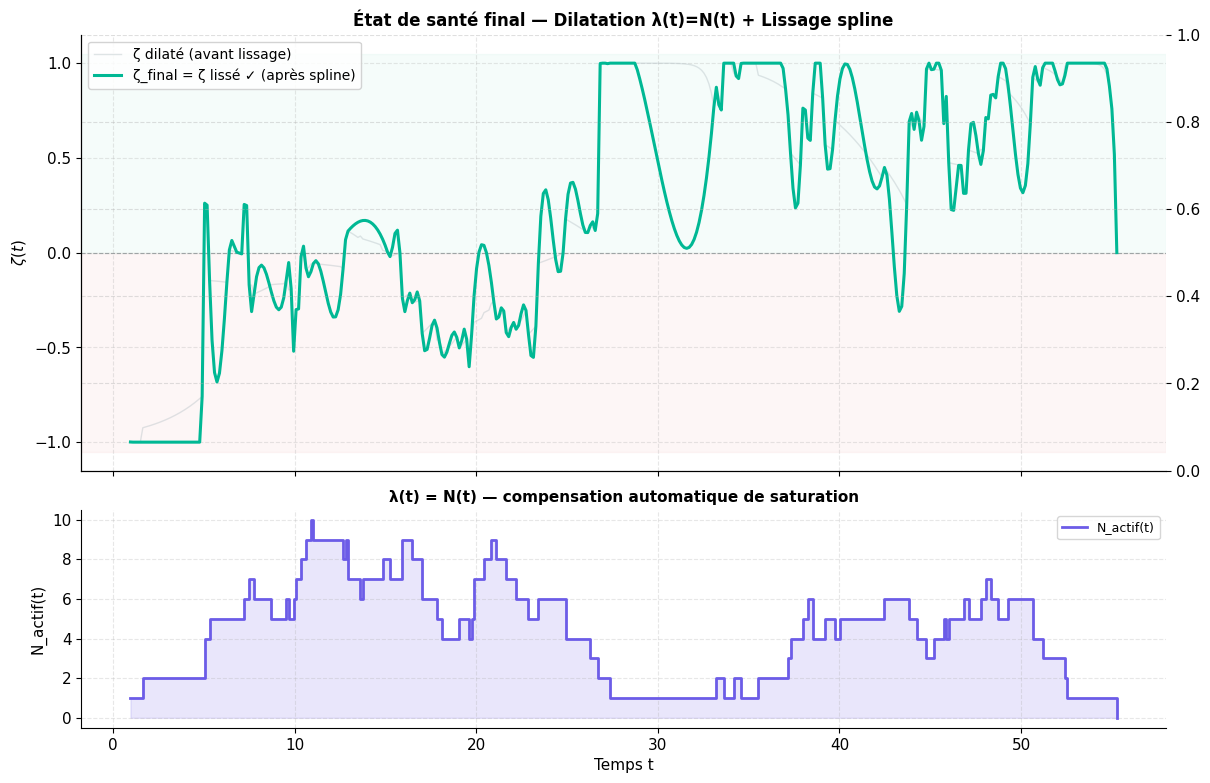

fig7_3_health_final.png


In [79]:
# GRAPHIQUE: Comparaison régimes de dilatation avec ζ_lissé

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True,
                         facecolor='white',
                         gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.12})

ax1 = axes[0]
ax1_r = ax1.twinx()

# Fonds colorés
ax1.axhspan( 0,  1.05, alpha=0.04, color=COLORS['pos'])
ax1.axhspan(-1.05, 0,  alpha=0.04, color=COLORS['neg'])
ax1.axhline(0, color=COLORS['gray'], lw=0.8, ls='--', alpha=0.5)

# Courbes
ax1.plot(t_grid, zeta_t_dilated, color='#b2bec3', lw=1.0, alpha=0.4, label='ζ dilaté (avant lissage)')
ax1.plot(t_grid, zeta_t_final,   color=COLORS['pos'], lw=2.2, label='ζ_final = ζ lissé ✓ (après spline)')
ax1.set_ylim(-1.15, 1.15)
ax1.set_ylabel(r'$\zeta(t)$', fontsize=11)
ax1.set_title('État de santé final — Dilatation λ(t)=N(t) + Lissage spline',
              fontsize=12, fontweight='bold')
ax1.legend(fontsize=10, framealpha=0.85, loc='upper left')
ax1.grid(True, alpha=0.3)

# Panneau 2 : Nombre d'événements actifs
ax2 = axes[1]
ax2.step(t_grid, N_actif, where='post', color=COLORS['count'], lw=2.0, label='N_actif(t)')
ax2.fill_between(t_grid, N_actif, step='post', alpha=0.15, color=COLORS['count'])
ax2.set_xlabel('Temps t', fontsize=11)
ax2.set_ylabel('N_actif(t)', fontsize=11)
ax2.set_title(f'λ(t) = N(t) — compensation automatique de saturation',
              fontsize=11, fontweight='bold')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

plt.savefig('fig7_3_health_final.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("fig7_3_health_final.png")


---
## 7.4 Apprentissage par Q-Learning - Signal amélioré

**Référence article :** §7.4

**CHANGE IN v9:** Q-Learning utilise maintenant **ζ_final (lissé)** au lieu de ζ brut.
Cela améliore la qualité du signal d'entraînement et la convergence de l'algorithme.

### Architecture MDP

L'agent optimise les paramètres (α, β, δ, γ) en minimisant la MAPE à travers :
- **État** : bin discret de MAPE courante
- **Action** : perturbation ±ε sur un paramètre
- **Récompense** : -ΔMAPE (positif si MAPE diminue)


In [80]:
# NOTE v9: UTILISATION DE ζ_final LISSÉ
# Cet entraînement Q-Learning utilise maintenant zeta_t_final (lissé)
# au lieu de zeta_t brut. Cela améliore la qualité du signal.
# Les améliorations de §7.1-7.2 propagent automatiquement ici.

# Paramètres du Q-Learning
QL_EPISODES    = 600       # plus d'épisodes pour explorer davantage
QL_LR          = 0.20      # taux d'apprentissage α_lr (réduit pour plus de stabilité)
QL_GAMMA       = 0.90      # facteur d'actualisation γ_rl
QL_EPS_START   = 1.00      # exploration initiale complète
QL_EPS_END     = 0.05      # plancher d'exploration
QL_EPS_DECAY   = 0.9965    # décroissance plus lente : ε=0.05 atteint à ~ep 500
                            # (vs ep 230 avec 0.990) → explore toute la Q-table
QL_STEP_INIT   = 0.20      # step initial large pour explorer loin de l'optimum
QL_STEP_MIN    = 0.01      # step minimal pour affiner près de l'optimum
PARAM_BOUNDS_QL = (0.05, 5.0)

# Espace d'états : 6 bins MAPE affinés
# Plus de bins → meilleure discrimination -> Q-table plus informative
MAPE_BINS = [0, 2, 4, 7, 12, 20, np.inf]    # 6 états
N_STATES  = len(MAPE_BINS) - 1

def mape_to_state(mape_val):
    for i in range(N_STATES):
        if MAPE_BINS[i] <= mape_val < MAPE_BINS[i + 1]:
            return i
    return N_STATES - 1

STATE_LABELS = [f'{MAPE_BINS[i]:.0f}–{MAPE_BINS[i+1]:.0f}%'
                if MAPE_BINS[i+1] != np.inf
                else f'>{MAPE_BINS[i]:.0f}%'
                for i in range(N_STATES)]

# Espace d'actions étendu : 3 amplitudes × 4 paramètres × 2 signes
# Step adaptatif selon la MAPE courante : grand quand loin, petit près de l'optimum
# On encode l'amplitude dans l'action elle-même (3 niveaux)
STEP_LEVELS = [0.20, 0.06, 0.01]   # large / moyen / fin
ACTIONS     = [(pi, sign, sl)
               for sl in range(len(STEP_LEVELS))
               for pi in range(4)
               for sign in (+1, -1)]
N_ACTIONS   = len(ACTIONS)         # 24 actions

ACTION_LABELS = [f'{"+" if s>0 else "-"}{STEP_LEVELS[sl]:.2f}·{["α","β","δ","γ"][p]}'
                 for p, s, sl in ACTIONS]

# Q-table initialisée à zéro (exploration neutre)
rng_ql  = np.random.default_rng(RANDOM_SEED + 10)
Q_table = np.zeros((N_STATES, N_ACTIONS))

def apply_action(params, action_idx):
    p = params.copy()
    pi, sign, sl = ACTIONS[action_idx]
    step = STEP_LEVELS[sl]
    p[pi] = np.clip(p[pi] + sign * step, *PARAM_BOUNDS_QL)
    return p


# Warm start depuis le gradient descent
params_ql = best.copy()
eps       = QL_EPS_START
mape_now  = mean_mape(params_ql, D_tr, F_tr, R_tr, P_tr, G_tr)

hist_mape_ql   = [mape_now]
hist_params_ql = [params_ql.copy()]
hist_eps       = [eps]
hist_states    = [mape_to_state(mape_now)]

visit_counts  = np.zeros((N_STATES, N_ACTIONS), dtype=int)
reward_totals = np.zeros((N_STATES, N_ACTIONS))

# Boucle principale
best_params_ever = params_ql.copy()
best_mape_ever   = mape_now

for ep in range(QL_EPISODES):
    s = mape_to_state(mape_now)

    # ε-greedy : forcer l'exploration des actions jamais testées dans cet état
    unvisited = np.where(visit_counts[s] == 0)[0]
    if len(unvisited) > 0 and rng_ql.random() < 0.50:
        # Priorité aux actions inexplorées dans l'état courant
        a = int(rng_ql.choice(unvisited))
    elif rng_ql.random() < eps:
        a = int(rng_ql.integers(N_ACTIONS))
    else:
        a = int(np.argmax(Q_table[s]))

    params_new = apply_action(params_ql, a)
    mape_new   = mean_mape(params_new, D_tr, F_tr, R_tr, P_tr, G_tr)
    reward     = mape_now - mape_new      # >0 si amélioration, <0 sinon
    s_next     = mape_to_state(mape_new)

    # Mise à jour Q-table (équation de Bellman)
    td_target      = reward + QL_GAMMA * np.max(Q_table[s_next])
    Q_table[s, a] += QL_LR * (td_target - Q_table[s, a])

    visit_counts[s, a]  += 1
    reward_totals[s, a] += reward

    # Acceptation : toujours si amélioration, sinon Metropolis-Hastings léger
    if mape_new < mape_now:
        params_ql = params_new
        mape_now  = mape_new
    elif rng_ql.random() < np.exp(-(mape_new - mape_now) / max(mape_now, 0.1)) * eps:
        # Acceptation probabiliste décroissante : permet d'échapper aux minima locaux
        params_ql = params_new
        mape_now  = mape_new

    # Garder le meilleur paramètre trouvé
    if mape_now < best_mape_ever:
        best_params_ever = params_ql.copy()
        best_mape_ever   = mape_now

    eps = max(QL_EPS_END, eps * QL_EPS_DECAY)

    hist_mape_ql.append(mape_now)
    hist_params_ql.append(params_ql.copy())
    hist_eps.append(eps)
    hist_states.append(mape_to_state(mape_now))

hist_params_ql = np.array(hist_params_ql)
best_ql        = best_params_ever.copy()   # meilleur params, pas le dernier
mape_ql_test   = mean_mape(best_ql, D_te, F_te, R_te, P_te, G_te)

with np.errstate(invalid='ignore'):
    avg_reward = np.where(visit_counts > 0,
                          reward_totals / np.maximum(visit_counts, 1),
                          np.nan)

n_states_visited  = int((visit_counts.sum(axis=1) > 0).sum())
n_actions_visited = int((visit_counts.sum(axis=0) > 0).sum())
coverage = visit_counts[visit_counts > 0].size / visit_counts.size * 100

print(f"Q-Learning terminé ({QL_EPISODES} épisodes)")
print(f"  Paramètres finaux : α={best_ql[0]:.4f} β={best_ql[1]:.4f} "
      f"δ={best_ql[2]:.4f} γ={best_ql[3]:.4f}")
print(f"  MAPE train : {best_mape_ever:.2f}%   MAPE test : {mape_ql_test:.2f}%")
print(f"  Gradient descent (test) : {history['mape_test'][-1]:.2f}%")
print(f"  États visités  : {n_states_visited}/{N_STATES}")
print(f"  Couverture Q-table : {coverage:.1f}%  ({visit_counts[visit_counts>0].size}/{visit_counts.size} cases)")


Q-Learning terminé (600 épisodes)
  Paramètres finaux : α=0.7904 β=0.6031 δ=0.4997 γ=1.1890
  MAPE train : 4.02%   MAPE test : 4.32%
  Gradient descent (test) : 4.32%
  États visités  : 4/6
  Couverture Q-table : 66.7%  (96/144 cases)


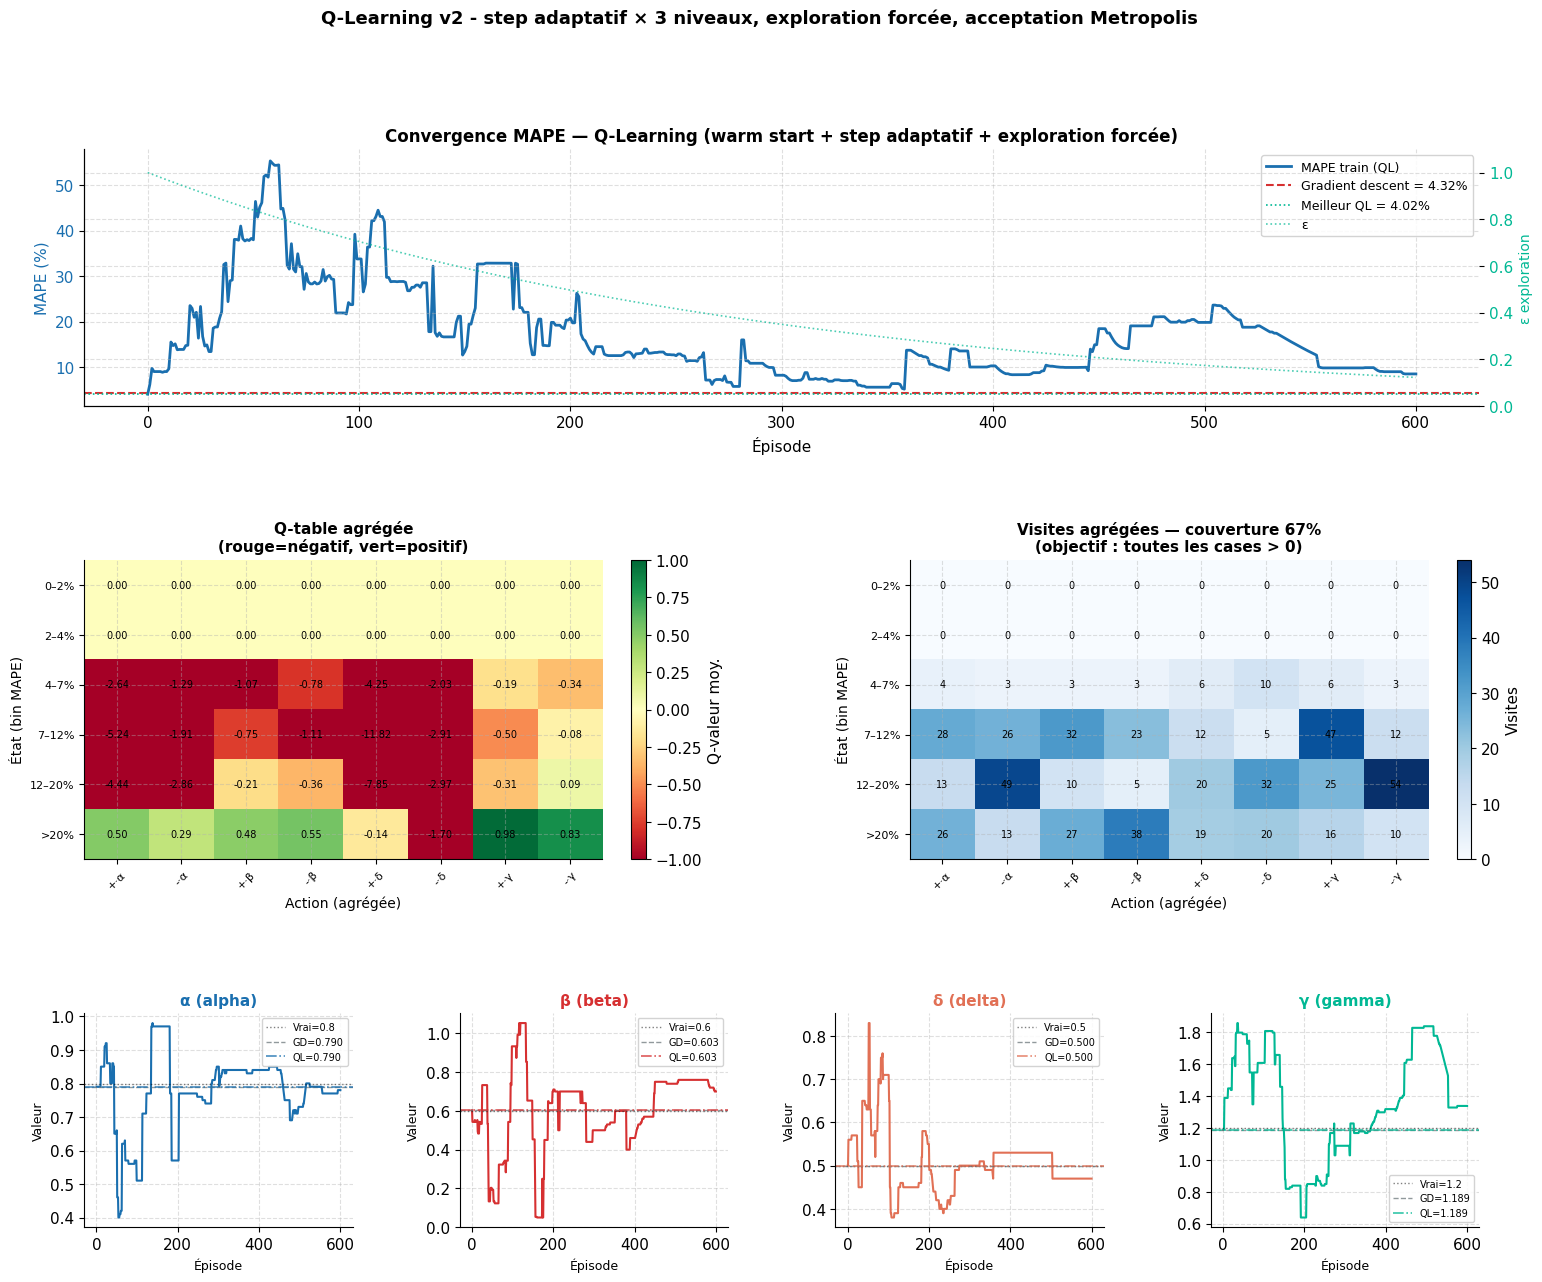

fig9_qlearning.png

Comparaison finale :
Gradient descent MAPE test : 4.32%
Q-Learning MAPE test : 4.32%
Couverture Q-table : 66.7%
Gain QL vs GD : +0.00 pp


In [81]:
# Graphique Q-Learning : convergence + Q-table + matrice visites
eps_arr  = np.array(hist_eps)
episodes = np.arange(len(hist_mape_ql))

fig = plt.figure(figsize=(18, 14), facecolor='white')
gs_outer = gridspec.GridSpec(3, 1, figure=fig,
                             hspace=0.60, height_ratios=[1.2, 1.4, 1])

# Ligne 1 : MAPE + ε
ax1   = fig.add_subplot(gs_outer[0])
ax1_r = ax1.twinx()
ax1.plot(episodes, hist_mape_ql, color=COLORS['blue'], lw=2.0, label='MAPE train (QL)')
ax1.axhline(history['mape_test'][-1], color=COLORS['neg'], lw=1.5, ls='--',
            label=f"Gradient descent = {history['mape_test'][-1]:.2f}%")
ax1.axhline(best_mape_ever, color=COLORS['pos'], lw=1.2, ls=':',
            label=f"Meilleur QL = {best_mape_ever:.2f}%")
ax1.set_ylabel('MAPE (%)', fontsize=11, color=COLORS['blue'])
ax1.tick_params(axis='y', labelcolor=COLORS['blue'])
ax1.set_title('Convergence MAPE — Q-Learning (warm start + step adaptatif + exploration forcée)',
              fontsize=12, fontweight='bold')
ax1_r.plot(episodes, eps_arr, color=COLORS['gamma'], lw=1.2, ls=':', alpha=0.7, label='ε')
ax1_r.set_ylabel("ε exploration", fontsize=10, color=COLORS['gamma'])
ax1_r.tick_params(axis='y', labelcolor=COLORS['gamma'])
ax1_r.set_ylim(0, 1.1)
lines1, lbl1 = ax1.get_legend_handles_labels()
lines2, lbl2 = ax1_r.get_legend_handles_labels()
ax1.legend(lines1 + lines2, lbl1 + lbl2, fontsize=9, framealpha=0.85)
ax1.set_xlabel('Épisode', fontsize=11)

# Ligne 2 : Q-table + matrice visites
gs2 = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_outer[1], wspace=0.45)

# Agréger par (état, paramètre × signe) pour réduire la dimensionnalité affichée
# On regroupe les 3 niveaux de step -> moyenne par (état, param, signe)
N_PARAM_ACTIONS = 4 * 2   # 8 actions résumées
Q_agg     = np.zeros((N_STATES, N_PARAM_ACTIONS))
V_agg     = np.zeros((N_STATES, N_PARAM_ACTIONS), dtype=int)
agg_labels = [f'{"+" if s>0 else "-"}·{["α","β","δ","γ"][p]}' for p in range(4) for s in (+1, -1)]

for ai, (pi, sign, sl) in enumerate(ACTIONS):
    col = pi * 2 + (0 if sign > 0 else 1)
    Q_agg[:, col] += Q_table[:, ai]
    V_agg[:, col] += visit_counts[:, ai]

Q_agg /= len(STEP_LEVELS)   # moyenne sur les 3 niveaux de step

ax_q = fig.add_subplot(gs2[0])
im_q = ax_q.imshow(Q_agg, aspect='auto', cmap='RdYlGn', vmin=-1, vmax=1)
ax_q.set_xticks(range(N_PARAM_ACTIONS))
ax_q.set_xticklabels(agg_labels, fontsize=8, rotation=45)
ax_q.set_yticks(range(N_STATES))
ax_q.set_yticklabels(STATE_LABELS, fontsize=8)
ax_q.set_xlabel('Action (agrégée)', fontsize=10)
ax_q.set_ylabel('État (bin MAPE)', fontsize=10)
ax_q.set_title('Q-table agrégée\n(rouge=négatif, vert=positif)', fontsize=11, fontweight='bold')
plt.colorbar(im_q, ax=ax_q, fraction=0.04, label='Q-valeur moy.')
for i in range(N_STATES):
    for j in range(N_PARAM_ACTIONS):
        ax_q.text(j, i, f'{Q_agg[i,j]:.2f}', ha='center', va='center',
                  fontsize=7, color='black')

ax_v = fig.add_subplot(gs2[1])
im_v = ax_v.imshow(V_agg, aspect='auto', cmap='Blues')
ax_v.set_xticks(range(N_PARAM_ACTIONS))
ax_v.set_xticklabels(agg_labels, fontsize=8, rotation=45)
ax_v.set_yticks(range(N_STATES))
ax_v.set_yticklabels(STATE_LABELS, fontsize=8)
ax_v.set_xlabel('Action (agrégée)', fontsize=10)
ax_v.set_ylabel('État (bin MAPE)', fontsize=10)
ax_v.set_title(f'Visites agrégées — couverture {coverage:.0f}%\n(objectif : toutes les cases > 0)',
               fontsize=11, fontweight='bold')
plt.colorbar(im_v, ax=ax_v, fraction=0.04, label='Visites')

for i in range(N_STATES):
    for j in range(N_PARAM_ACTIONS):
        ax_v.text(j, i, str(V_agg[i, j]), ha='center', va='center',
                  fontsize=7, color='black')

# Ligne 3 : évolution des 4 paramètres
gs3 = gridspec.GridSpecFromSubplotSpec(1, 4, subplot_spec=gs_outer[2], wspace=0.40)
for pi in range(4):
    ax = fig.add_subplot(gs3[pi])
    ax.plot(episodes, hist_params_ql[:, pi], color=PARAM_COLORS[pi], lw=1.5)
    ax.axhline(TRUE_PARAMS[pi], color='black', lw=1.0, ls=':', alpha=0.5,
               label=f'Vrai={TRUE_PARAMS[pi]}')
    ax.axhline(best[pi], color=COLORS['gray'], lw=1.0, ls='--', alpha=0.7,
               label=f'GD={best[pi]:.3f}')
    ax.axhline(best_ql[pi], color=PARAM_COLORS[pi], lw=1.2, ls='-.', alpha=0.8,
               label=f'QL={best_ql[pi]:.3f}')
    ax.set_title(PARAM_NAMES[pi], fontsize=11, fontweight='bold', color=PARAM_COLORS[pi])
    ax.set_xlabel('Épisode', fontsize=9)
    ax.set_ylabel('Valeur', fontsize=9)
    ax.legend(fontsize=7, framealpha=0.85)

fig.suptitle("Q-Learning v2 - step adaptatif × 3 niveaux, exploration forcée, acceptation Metropolis",
             fontsize=13, fontweight='bold')
plt.savefig('fig9_qlearning.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("fig9_qlearning.png")

print(f"\nComparaison finale :")
print(f"Gradient descent MAPE test : {history['mape_test'][-1]:.2f}%")
print(f"Q-Learning MAPE test : {mape_ql_test:.2f}%")
print(f"Couverture Q-table : {coverage:.1f}%")
print(f"Gain QL vs GD : {history['mape_test'][-1] - mape_ql_test:+.2f} pp")


---
## 18. Synthèse des résultats

**Référence article :** §8 - *Synthèse du modèle* (Table 2)

### Chaîne de transformation (Éq. 40)

$$\{e_i\} \xrightarrow{\Gamma_{\hat{\theta}_{k(i)}}(t)} G(t) \xrightarrow{I+W(t)} G^e(t) \xrightarrow{\langle\bar{\omega},\cdot\rangle} S(t) \xrightarrow{\tanh(\cdot/\lambda)} \zeta_\lambda(E(t)) \in (-1,1)$$

### Tableau de synthèse des objets mathématiques

| Objet | Définition | Espace | Référence |
|-------|-----------|--------|-----------|
| Événement $e_i$ | $(D, F, R, P)$ | $\mathbb{R}^4$ | Déf. 2.3 |
| Gravité résiduelle $G_i(t)$ | $D_{\text{eff}}^\alpha F^\beta R^\delta/(1+P^\gamma)$ | $\mathbb{R}^+$ | Déf. 3.3 |
| Matrice $W(t)$ | $[W_{ij}(t)]$ | $\mathbb{R}^{N\times N}$ | Déf. 4.2 |
| Gravité eff. $G^e_i$ | $(I+W)G$ | $\mathbb{R}$ | Déf. 4.3 |
| Poids $\omega_i$ (statique) | $\in [-\omega_{\max}, \omega_{\max}]$ | $\mathbb{R}$ | Déf. 6.3 |
| Drap $f^*$ | $\arg\min \bar{I}(f)$ | $C^\infty(\Omega)$ | Déf. 6.8 |
| Poids norm. $\bar{\omega}_i$ | $\omega_i/\|\omega\|_1$ | $\mathbb{R}$ | Déf. 6.4 |
| État de santé $\zeta_\lambda$ | $\tanh\!\bigl(\tfrac{1}{\lambda}\sum_i \bar{\omega}_i G^e_i\bigr)$ | $(-1,1)$ | Éq. 23 |


---
## A. Gravité résiduelle temporelle - Deff(t)

**Référence article :** §3.3 - *Intégration de la dynamique temporelle dans Γ*

L'article introduit une durée **effective** qui décroît au cours du temps :

$$D_{\text{eff}}(t) = \max\bigl(D - (t - t_0),\; 0\bigr)$$

La gravité devient alors **temporellement dépendante** :

$$G(t) = \Gamma\bigl(D_{\text{eff}}(t), F, R, P\bigr)
       = \frac{\max(D-(t-t_0), 0)^{\alpha} \cdot F^{\beta} \cdot R^{\delta}}
              {1 + P^{\gamma}}$$

Propriété clé : dès $t \geq t_0 + D$, $G(t) = 0$ exactement — l'événement
s'éteint naturellement. Les poids $\omega_i$ restent **statiques** ; c'est
$D_{\text{eff}}(t)$ qui pilote l'extinction temporelle.


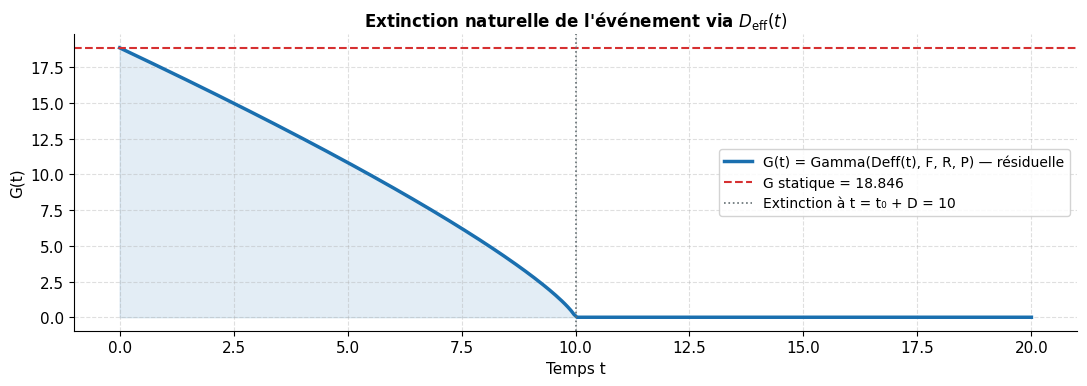

G statique   = 18.8464
G(t=5) = 10.8244
G(t=D) = 0.000000  (extinction)
figA_gravite_residuelle.png


In [82]:
# Illustration : extinction temporelle d'un événement
alpha_demo, beta_demo, delta_demo, gamma_demo = 0.8, 0.6, 0.5, 1.2
D_demo, F_demo, R_demo, P_demo = 10.0, 2.0, 8.0, 0.5
t0_demo = 0.0

t_range = np.linspace(0, 20, 300)
G_static   = gravity(D_demo, F_demo, R_demo, P_demo,
                     alpha_demo, beta_demo, delta_demo, gamma_demo)
G_residual = gravity_residual(D_demo, F_demo, R_demo, P_demo,
                               alpha_demo, beta_demo, delta_demo, gamma_demo,
                               t_range, t0_demo)

fig, ax = plt.subplots(figsize=(11, 4), facecolor='white')
ax.plot(t_range, G_residual, color=COLORS['blue'], lw=2.5,
        label='G(t) = Gamma(Deff(t), F, R, P) — résiduelle')
ax.axhline(G_static, color=COLORS['neg'], lw=1.5, ls='--',
           label=f'G statique = {G_static:.3f}')
ax.axvline(D_demo + t0_demo, color=COLORS['gray'], lw=1.2, ls=':',
           label=f'Extinction à t = t₀ + D = {D_demo:.0f}')
ax.fill_between(t_range, G_residual, alpha=0.12, color=COLORS['blue'])
ax.set_xlabel('Temps t', fontsize=11)
ax.set_ylabel('G(t)', fontsize=11)
ax.set_title("Extinction naturelle de l'événement via $D_{\\mathrm{eff}}(t)$",
             fontsize=12, fontweight='bold')
ax.legend(fontsize=10, framealpha=0.85)
plt.tight_layout()
plt.savefig('figA_gravite_residuelle.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()
print(f"G statique   = {G_static:.4f}")
print(f"G(t=5) = {gravity_residual(D_demo,F_demo,R_demo,P_demo,alpha_demo,beta_demo,delta_demo,gamma_demo,5,t0_demo):.4f}")
print(f"G(t=D) = {gravity_residual(D_demo,F_demo,R_demo,P_demo,alpha_demo,beta_demo,delta_demo,gamma_demo,D_demo,t0_demo):.6f}  (extinction)")
print("figA_gravite_residuelle.png")


---
## B. Poids statiques, normalisation L¹ et λ(t) = N(t)

**Référence article :** §6.4 et §7.1

### Changement de modèle : poids statiques vs dynamiques

L'article final adopte des **poids statiques** $\omega_i \in [-\omega_{\max}, \omega_{\max}]$
(indépendants du temps). L'extinction temporelle de l'influence est entièrement
gérée par $D_{\text{eff}}(t)$ dans $\Gamma$. Cela remplace les poids dynamiques
$\omega_i(t) = \omega_i(0) e^{-\lambda_i t}$ des versions précédentes.

### Normalisation L¹ (Déf. 6.4)

$$\bar{\omega}_i = \frac{\omega_i}{\displaystyle\sum_{j=1}^{N(t)} |\omega_j|}
\qquad \Rightarrow \qquad \sum_{i=1}^{N(t)} |\bar{\omega}_i| = 1$$

**Propriétés (Prop. 6.2) :**
- *Invariance à l'échelle* : multiplier tous les $\omega_i$ par $c > 0$ ne change pas $\zeta$
- *Stabilité* : ajouter un événement neutre ($\omega = 0$) ne modifie pas $S(t)$
- *Borne de contrôle* : $|S(t)| \leq \max_i |G^e_i(t)|$

### λ dynamique (§7.1, Éq. 27)

Pour corriger le problème d'échelle quand beaucoup d'événements s'accumulent :

$$\lambda(t) = N(t)$$

où $N(t)$ est le nombre d'événements actifs à l'instant $t$. La dilatation
est ainsi proportionnelle à la densité informationnelle du système.


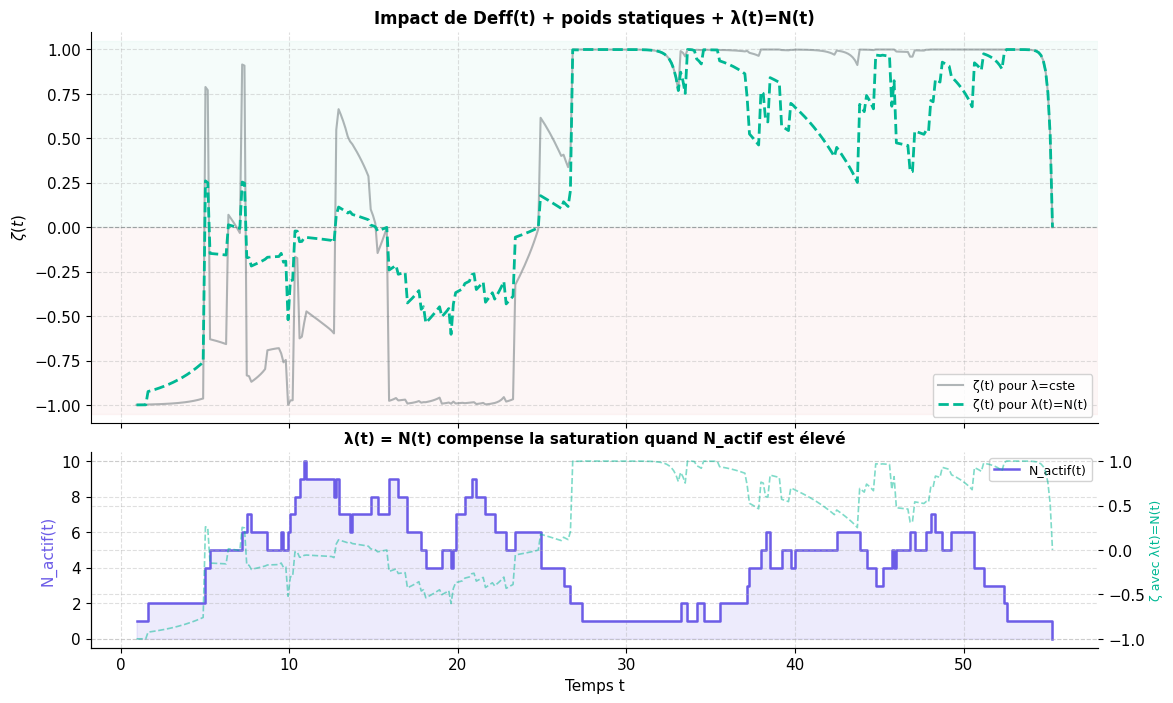

figB_static_weights_deff.png


In [83]:
def health_static_weights(G_eff, omega_static):
    """
    Opérateur ζ avec poids statiques normalisés L1 (Déf. 6.4).

    omega_static : poids fixes (pas de décroissance temporelle)
    """
    
    w = np.array(omega_static, dtype=float)
    norm = np.sum(np.abs(w))
    if norm < 1e-12:
        return 0.0
        
    return float(np.tanh(np.dot(w / norm, G_eff)))


def compute_health_residual_static(
        D_test, F_test, R_test, P_test,
        t0_test, omega_static, params,
        W_matrix=None, t_resolution=400,
        use_dynamic_lambda=False):
    """
    ζ(t) avec gravité résiduelle Deff(t) + poids statiques + normalisation L1.

    Si use_dynamic_lambda=True, λ(t) = N_actif(t) (§7.1 Éq. 27).
    Sinon λ=1 (standard).
    """
    
    alpha, beta, delta, gamma = params
    t_end  = t0_test + D_test
    t_grid = np.linspace(t0_test.min(), t_end.max(), t_resolution)

    zeta_t  = np.zeros(t_resolution)
    n_actif = np.zeros(t_resolution, dtype=int)

    for k, t in enumerate(t_grid):
        mask = (t0_test <= t) & (t < t_end)
        n_k  = mask.sum()
        n_actif[k] = int(n_k)
        if n_k == 0:
            continue

        # Gravité résiduelle
        Gk = gravity_residual(D_test[mask], F_test[mask],
                               R_test[mask], P_test[mask],
                               alpha, beta, delta, gamma,
                               t, t0_test[mask])

        # Gravité effective via W(t)
        if W_matrix is not None:
            idx_a = np.where(mask)[0]
            Wk    = W_matrix[np.ix_(idx_a, idx_a)]
            G_eff = (np.eye(n_k) + Wk) @ Gk
        else:
            G_eff = Gk.copy()

        # Poids statiques normalisés L1
        w_k  = omega_static[mask]
        norm = np.sum(np.abs(w_k))
        if norm < 1e-12:
            zeta_t[k] = 0.0
            continue

        S = np.dot(w_k / norm, G_eff)

        # λ(t) = N(t) si mode dynamique, sinon λ=1
        lam = float(n_k) if use_dynamic_lambda else 1.0
        zeta_t[k] = float(np.tanh(S / lam))

    return t_grid, zeta_t, n_actif


# Calcul avec les deux modes
# Poids statiques tirés de OMEGA0_te (valeurs initiales, sans décroissance)
omega_static_te = OMEGA0_te.copy()

t_res, zeta_res_lam1, n_act_res = compute_health_residual_static(
    D_te, F_te, R_te, P_te, T_te,
    omega_static_te, best, W_matrix=W_test,
    use_dynamic_lambda=False, t_resolution=400,
)
_, zeta_res_lamN, _ = compute_health_residual_static(
    D_te, F_te, R_te, P_te, T_te,
    omega_static_te, best, W_matrix=W_test,
    use_dynamic_lambda=True, t_resolution=400,
)

# Graphique comparatif
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                         facecolor='white',
                         gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.10})

ax1 = axes[0]
ax1.axhspan( 0,  1.05, alpha=0.04, color=COLORS['pos'])
ax1.axhspan(-1.05, 0,  alpha=0.04, color=COLORS['neg'])
ax1.axhline(0, color=COLORS['gray'], lw=0.8, ls='--', alpha=0.5)
ax1.plot(t_grid, zeta_t, color=COLORS['gray'], lw=1.5, alpha=0.5,
         label='ζ(t) pour λ=cste')

ax1.plot(t_res,  zeta_res_lamN, color=COLORS['pos'],  lw=2.0, ls='--',
         label='ζ(t) pour λ(t)=N(t)')
ax1.set_ylim(-1.1, 1.1)
ax1.set_ylabel(r'$\zeta(t)$', fontsize=11)
ax1.set_title("Impact de Deff(t) + poids statiques + λ(t)=N(t)",
              fontsize=12, fontweight='bold')
ax1.legend(fontsize=9, framealpha=0.85)

ax2 = axes[1]
ax2_r = ax2.twinx()
ax2.step(t_res, n_act_res, where='post',
         color=COLORS['count'], lw=1.8, label='N_actif(t)')
ax2.fill_between(t_res, n_act_res, step='post', alpha=0.12, color=COLORS['count'])
ax2_r.plot(t_res, zeta_res_lamN, color=COLORS['pos'], lw=1.2, ls='--', alpha=0.5)
ax2.set_xlabel('Temps t', fontsize=11)
ax2.set_ylabel('N_actif(t)', fontsize=11, color=COLORS['count'])
ax2_r.set_ylabel('ζ avec λ(t)=N(t)', fontsize=9, color=COLORS['pos'])
ax2.set_title('λ(t) = N(t) compense la saturation quand N_actif est élevé',
              fontsize=11, fontweight='bold')
ax2.legend(fontsize=9, framealpha=0.85)

plt.savefig('figB_static_weights_deff.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()
print("figB_static_weights_deff.png")


---
## C. Drap variationnel de poids - $f^{(n)}(x, y)$

**Référence article :** §6.5 - *Construction d'un drap de poids par minimisation variationnelle*

### Principe

On cherche une surface continue $f^*(x, y)$ interpolant les poids observés
$\{(x_j, y_j, \omega_j)\}$ en minimisant la fonctionnelle d'énergie normalisée :

$$\bar{I}(f) = \frac{1}{L_x L_y} \iint_\Omega
\left[\left(\frac{\partial f}{\partial x}\right)^2
     + \left(\frac{\partial f}{\partial y}\right)^2\right] dx\, dy$$

### Forme paramétrique polynomiale (Déf. 6.10 — Éq. 21)

$$f_{\boldsymbol{\lambda}}^{(n)}(x, y)
= \sum_{\substack{i,j\,\geq\,0 \\ i+j\,\leq\, n}}
  \lambda_{ij}\, x^i y^j$$

Le nombre de paramètres vaut $\binom{n+2}{2} = \frac{(n+1)(n+2)}{2}$ :

| $n$ | Nb de termes | Forme |
|-----|-------------|-------|
| 1 | 3 | plan affine — aucune interaction |
| 2 | 6 | quadratique — couvre les 3 régimes de torsion |
| 3 | 10 | cubique — courbures locales |
| 4 | 15 | quartique |

**Proposition (convergence) :** $\mathrm{RMSE}(n)$ est décroissante en $n$.
Le degré optimal est :

$$n^* = \arg\min_n\left[\mathrm{RMSE}(n) + \mu\,\frac{\binom{n+2}{2}}{m}\right]$$

où $m = |\mathcal{C}_k|$ et $\mu > 0$ pénalise la complexité.
On visualise ici l'évolution de la précision en fonction de $n$.


Cluster 1 (6 pts) | n*=1 (3 params) | RMSE(n*)=0.3695 | Ī(f*)=0.3514
Cluster 2 (17 pts) | n*=1 (3 params) | RMSE(n*)=0.8990 | Ī(f*)=0.0029
Cluster 3 (22 pts) | n*=2 (6 params) | RMSE(n*)=0.8632 | Ī(f*)=1.6994


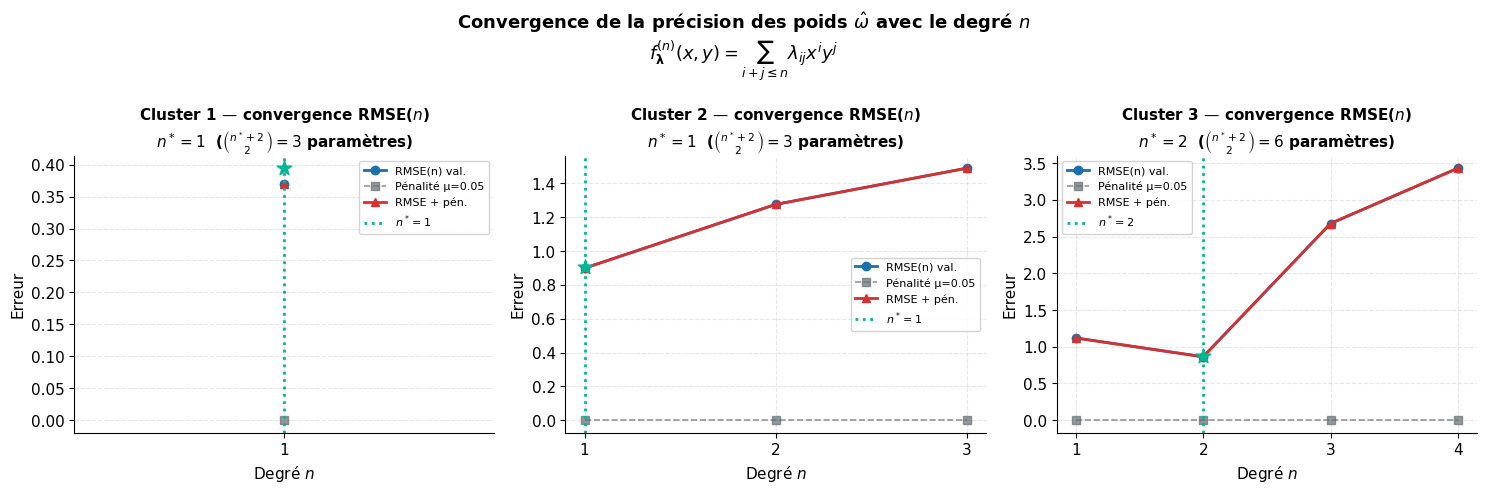

OK figC_drap_convergence.png


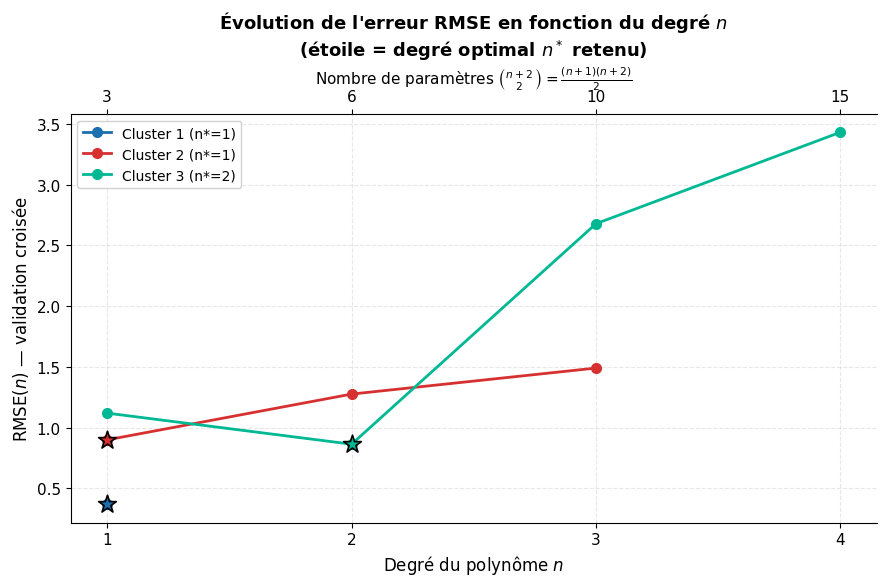

figC_erreur_vs_n.png


figC_draps_3D_interactif.html (version interactive)
⚠ Image statique non générée (installer kaleido) : 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido


Draps variationnels interactifs — degré optimal n*
Prédiction poids nouvel événement (D=4, F=2) :
    Cluster 1 (n*=1) → ω̂ = -0.3711
    Cluster 2 (n*=1) → ω̂ = 0.3981
    Cluster 3 (n*=2) → ω̂ = -0.0970
Temps d'entraînement ≈ p^0.68  (p = nb. paramètres)


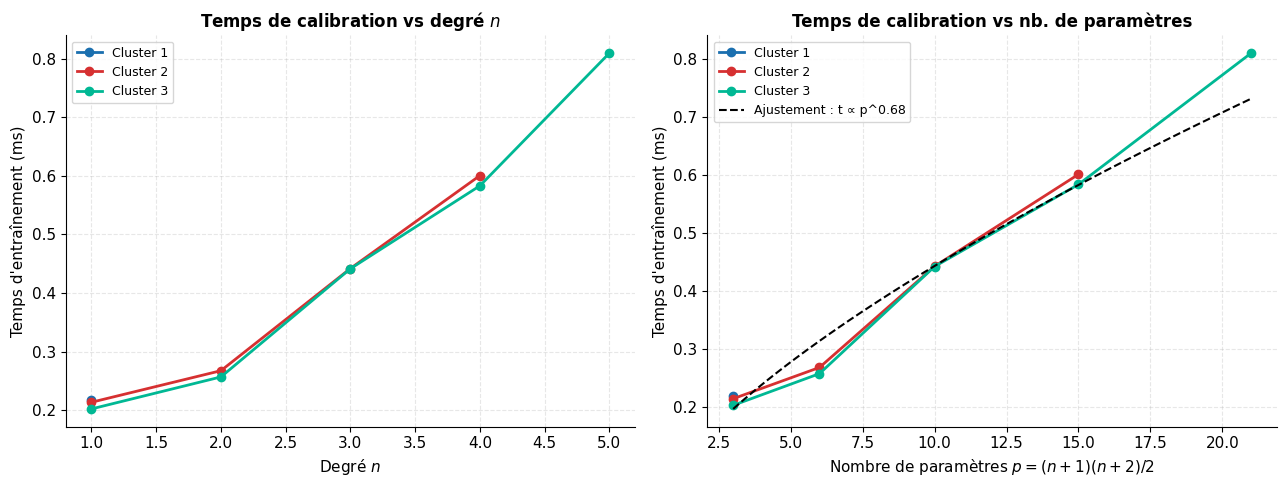

figC_temps_entrainement.png


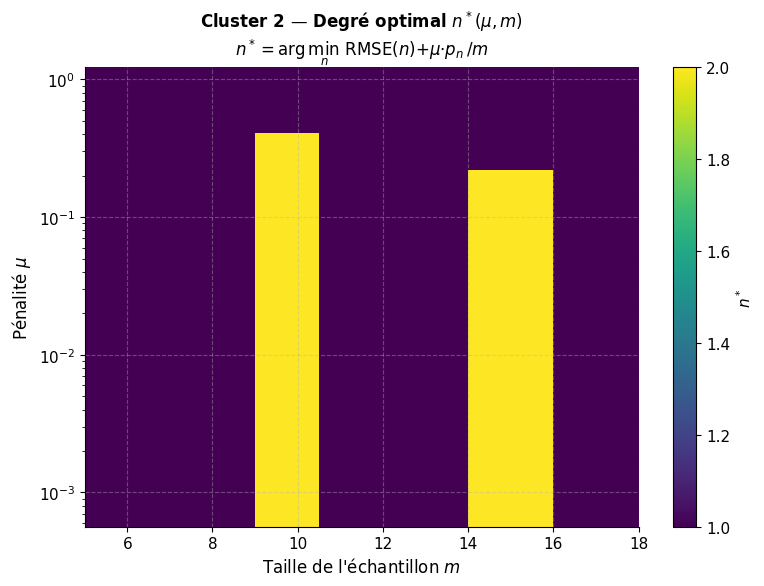

OK figC_sensibilite_nstar_cluster2.png


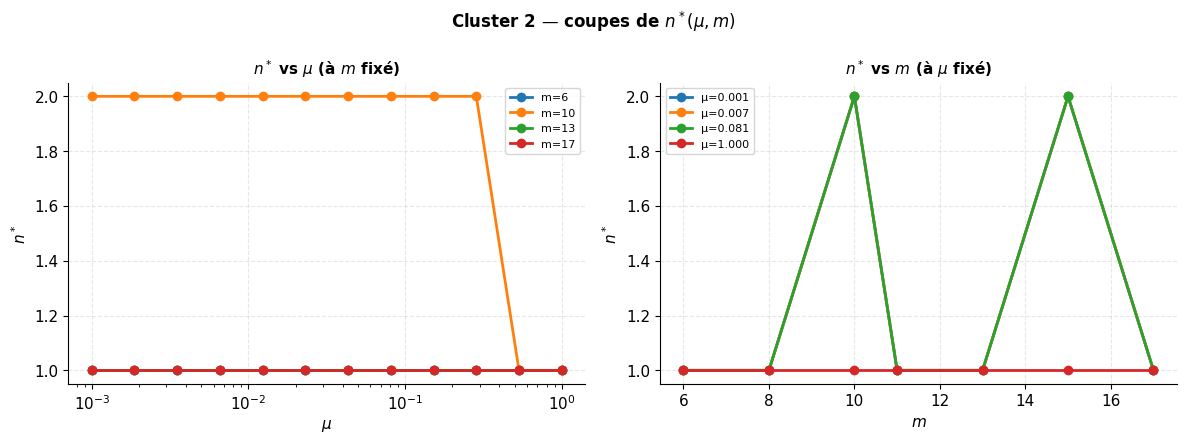

OK figC_coupes_nstar_cluster2.png


In [ ]:
from scipy.linalg import lstsq as sp_lstsq
from itertools import product as iproduct

# Utilitaires polynomiaux

def poly_features(X, Y, n):
    """
    Construit la matrice de design pour le polynôme de degré total <= n.
    Colonnes : x^i * y^j pour (i,j) avec i+j <= n, ordonnés par degré total.
    Nombre de colonnes : (n+1)(n+2)/2
    """
    
    cols = []
    for deg in range(n + 1):
        for i in range(deg + 1):
            j = deg - i
            cols.append(X**i * Y**j)
            
    return np.column_stack(cols)


def poly_basis_labels(n):
    """Labels des monômes x^i y^j pour i+j <= n."""
    
    labels = []
    for deg in range(n + 1):
        for i in range(deg + 1):
            j = deg - i
            xi = f'x^{i}' if i > 1 else ('x' if i == 1 else '1')
            yj = f'y^{j}' if j > 1 else ('y' if j == 1 else '')
            labels.append((xi + yj).strip('1') or '1')
            
    return labels


def fit_poly_surface(X, Y, Z, n):
    """
    Calibre f_lambda^(n) par moindres carrés.
    Retourne (lambda_hat, predict_fn, grille (XX, YY, ZZ)).
    """
    
    A = poly_features(X, Y, n)
    lam_hat, _, _, _ = sp_lstsq(A, Z)

    def predict(x, y):
        A_pred = poly_features(np.asarray(x).ravel(), np.asarray(y).ravel(), n)
        
        return (A_pred @ lam_hat).reshape(np.asarray(x).shape)

    x_lin = np.linspace(X.min(), X.max(), 40)
    y_lin = np.linspace(Y.min(), Y.max(), 40)
    XX, YY = np.meshgrid(x_lin, y_lin)
    ZZ = predict(XX, YY)
    
    return lam_hat, predict, (XX, YY, ZZ)


def normalized_energy_poly(lam, X, Y, n):
    """Calcule I_bar(f_lambda^(n)) par intégration numérique."""
    
    Lx = max(X.max() - X.min(), 1e-8)
    Ly = max(Y.max() - Y.min(), 1e-8)
    x_s = np.linspace(X.min(), X.max(), 60)
    y_s = np.linspace(Y.min(), Y.max(), 60)
    XX_s, YY_s = np.meshgrid(x_s, y_s)

    # df/dx : dérivée de chaque monôme x^i y^j par rapport à x
    dfdx = np.zeros_like(XX_s)
    dfdy = np.zeros_like(XX_s)
    idx = 0
    for deg in range(n + 1):
        for i in range(deg + 1):
            j = deg - i
            c = lam[idx]
            if i >= 1:
                dfdx += c * i * XX_s**(i-1) * YY_s**j
            if j >= 1:
                dfdy += c * j * XX_s**i * YY_s**(j-1)
            idx += 1

    integrand = dfdx**2 + dfdy**2
    
    return np.trapz(np.trapz(integrand, x_s, axis=1), y_s) / (Lx * Ly)


# Étude de convergence RMSE(n) par cluster

N_DEGREES  = list(range(1, 7))    # n = 1 … 6
MU_REG     = 0.05                  # facteur de pénalisation de complexité

fig_conv, axes_conv = plt.subplots(
    1, N_CLUSTERS, figsize=(5 * N_CLUSTERS, 5),
    facecolor='white', sharey=False
)

rmse_table   = {}   # {cluster_idx: {n: rmse}}
nstar_table  = {}   # {cluster_idx: n*}
best_preds   = {}   # {cluster_idx: predict_fn}

for k in range(N_CLUSTERS):
    mask_k = CLUSTER_te == k
    if mask_k.sum() < 6:
        print(f"Cluster {k+1} : pas assez de points ({mask_k.sum()}) — ignoré")
        continue

    Xk = D_te[mask_k]
    Yk = F_te[mask_k]
    Zk = OMEGA0_te[mask_k]
    m  = len(Zk)

    # Validation croisée Leave-One-Out allégée (80/20 sur 5 splits aléatoires)
    rng_cv = np.random.default_rng(RANDOM_SEED + 200 + k)
    n_val  = max(1, m // 5)
    N_SPLITS_DRAP = 8

    rmse_by_n   = {}
    energy_by_n = {}

    for n in N_DEGREES:
        n_params = (n + 1) * (n + 2) // 2
        if n_params >= m:
            break   # sur-déterminé : arrêt

        rmses = []
        for _ in range(N_SPLITS_DRAP):
            idx_val  = rng_cv.choice(m, size=n_val, replace=False)
            idx_tr   = np.setdiff1d(np.arange(m), idx_val)
            if len(idx_tr) < n_params:
                continue
            lam_tr, pred_tr, _ = fit_poly_surface(
                Xk[idx_tr], Yk[idx_tr], Zk[idx_tr], n)
            z_pred = pred_tr(Xk[idx_val], Yk[idx_val])
            rmses.append(np.sqrt(np.mean((z_pred - Zk[idx_val])**2)))

        if not rmses:
            continue
        rmse_cv = float(np.mean(rmses))
        pen     = MU_REG * n_params / m
        rmse_by_n[n]   = rmse_cv
        energy_by_n[n] = rmse_cv + pen

    if not rmse_by_n:
        continue

    rmse_table[k]  = rmse_by_n
    n_star         = min(energy_by_n, key=energy_by_n.get)
    nstar_table[k] = n_star

    # Ajuster le drap optimal sur toutes les données
    lam_best, pred_best, (XX_b, YY_b, ZZ_b) = fit_poly_surface(Xk, Yk, Zk, n_star)
    energy_best = normalized_energy_poly(lam_best, Xk, Yk, n_star)
    best_preds[k] = pred_best

    # Graphique RMSE(n)
    ax = axes_conv[k] if N_CLUSTERS > 1 else axes_conv
    ns     = list(rmse_by_n.keys())
    rmses  = list(rmse_by_n.values())
    pen_v  = [MU_REG * (n+1)*(n+2)//2 / m for n in ns]
    total  = [r + p for r, p in zip(rmses, pen_v)]

    ax.plot(ns, rmses,  'o-', color=COLORS['blue'],  lw=2,   label='RMSE(n) val.')
    ax.plot(ns, pen_v,  's--',color=COLORS['gray'],  lw=1.2, label=f'Pénalité μ={MU_REG}', alpha=0.7)
    ax.plot(ns, total,  '^-', color=COLORS['neg'],   lw=2,   label='RMSE + pén.')
    ax.axvline(n_star, color=COLORS['pos'], lw=2, ls=':', label=f'$n^*={n_star}$')
    ax.scatter([n_star], [energy_by_n[n_star]],
               s=120, zorder=5, color=COLORS['pos'], marker='*')
    ax.set_xlabel('Degré $n$', fontsize=11)
    ax.set_ylabel('Erreur', fontsize=11)
    ax.set_title(
        f'Cluster {k+1} — convergence RMSE($n$)\n'
        f'$n^*={n_star}$  ($\\binom{{n^*+2}}{{2}}='
        f'{(n_star+1)*(n_star+2)//2}$ paramètres)',
        fontsize=11, fontweight='bold')
    ax.legend(fontsize=8, framealpha=0.85)
    ax.set_xticks(ns)
    ax.grid(True, alpha=0.3)

    n_params_star = (n_star + 1) * (n_star + 2) // 2
    print(f"Cluster {k+1} ({m} pts) | n*={n_star} "
          f"({n_params_star} params) | "
          f"RMSE(n*)={rmse_by_n[n_star]:.4f} | Ī(f*)={energy_best:.4f}")

plt.suptitle(
    r"Convergence de la précision des poids $\hat{\omega}$ avec le degré $n$"
    "\n"
    r"$f_{\boldsymbol{\lambda}}^{(n)}(x,y) = \sum_{i+j\leq n}\lambda_{ij} x^i y^j$",
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig('figC_drap_convergence.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()
print("OK figC_drap_convergence.png")


# ═══════════════════════════════════════════════════════════════════════
# NOUVEAU — Graphique dédié : évolution de l'erreur en fonction de n SEUL
# (RMSE seule, sans la pénalité ni le total, avec le nombre de paramètres
#  associé affiché sur un axe secondaire)
# ═══════════════════════════════════════════════════════════════════════

fig_err, ax_err = plt.subplots(figsize=(9, 6), facecolor='white')

palette_clusters = [COLORS['blue'], COLORS['neg'], COLORS['pos'],
                     '#fdcb6e', '#6c5ce7', '#e17055']

for k in sorted(rmse_table.keys()):
    ns    = sorted(rmse_table[k].keys())
    rmses = [rmse_table[k][n] for n in ns]
    color = palette_clusters[k % len(palette_clusters)]

    ax_err.plot(ns, rmses, 'o-', lw=2, markersize=7, color=color,
                label=f'Cluster {k+1} (n*={nstar_table[k]})')

    # Marqueur distinctif sur le degré optimal n*
    n_star = nstar_table[k]
    ax_err.scatter([n_star], [rmse_table[k][n_star]],
                    s=180, zorder=5, marker='*', color=color,
                    edgecolor='black', linewidth=1.2)

ax_err.set_xlabel('Degré du polynôme $n$', fontsize=12)
ax_err.set_ylabel('RMSE($n$) — validation croisée', fontsize=12)
ax_err.set_title(
    "Évolution de l'erreur RMSE en fonction du degré $n$\n"
    "(étoile = degré optimal $n^*$ retenu)",
    fontsize=13, fontweight='bold'
)
ax_err.legend(fontsize=10, framealpha=0.9)
ax_err.grid(True, alpha=0.3)

all_ns = sorted(set(n for d in rmse_table.values() for n in d.keys()))
ax_err.set_xticks(all_ns)

# Axe secondaire (haut) : nombre de paramètres correspondant à chaque n
ax_params = ax_err.secondary_xaxis(
    'top', functions=(lambda n: n, lambda n: n)
)
ax_params.set_xticks(all_ns)
ax_params.set_xticklabels([f'{(n+1)*(n+2)//2}' for n in all_ns])
ax_params.set_xlabel(
    r'Nombre de paramètres $\binom{n+2}{2} = \frac{(n+1)(n+2)}{2}$',
    fontsize=11
)

plt.tight_layout()
plt.savefig('figC_erreur_vs_n.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()
print("figC_erreur_vs_n.png")


# Visualisation 3D du drap optimal pour chaque cluster
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, HTML

fig_draps = make_subplots(
    rows=1, cols=N_CLUSTERS,
    subplot_titles=[
        f'Cluster {k+1} — drap f*(D,F)  n*={nstar_table.get(k,"?")} '
        f'({(nstar_table.get(k,1)+1)*(nstar_table.get(k,1)+2)//2} params)'
        for k in range(N_CLUSTERS)
    ],
    specs=[[{'type': 'surface'}] * N_CLUSTERS],
    horizontal_spacing=0.05,
)

for k in range(N_CLUSTERS):
    if k not in best_preds:
        continue
    mask_k = CLUSTER_te == k
    Xk = D_te[mask_k];  Yk = F_te[mask_k];  Zk = OMEGA0_te[mask_k]
    n_star = nstar_table[k]
    _, _, (XX_b, YY_b, ZZ_b) = fit_poly_surface(Xk, Yk, Zk, n_star)

    fig_draps.add_trace(go.Surface(
        x=XX_b, y=YY_b, z=ZZ_b,
        colorscale='RdYlGn', opacity=0.60,
        showscale=(k == 0),
        name=f'C{k+1} drap',
        hovertemplate='D=%{x:.1f}<br>F=%{y:.1f}<br>ω=%{z:.3f}<extra></extra>',
    ), row=1, col=k+1)

    fig_draps.add_trace(go.Scatter3d(
        x=Xk, y=Yk, z=Zk, mode='markers',
        marker=dict(size=5,
                    color=['#00b894' if w >= 0 else '#d63031' for w in Zk]),
        name=f'C{k+1} obs',
        hovertemplate='D=%{x:.2f}<br>F=%{y:.2f}<br>ω=%{z:.3f}<extra></extra>',
    ), row=1, col=k+1)

fig_draps.update_layout(
    title=dict(
        text='Draps variationnels f*(D,F) — degré optimal n* par cluster<br>'
             '<sup>Points verts : ω > 0 (favorables) | points rouges : ω < 0 (défavorables)</sup>',
        font=dict(size=13)),
    height=500, showlegend=False, paper_bgcolor='white',
)
for sk in ['scene', 'scene2', 'scene3']:
    fig_draps.update_layout(**{sk: dict(
        xaxis_title='Durée D',
        yaxis_title='Fréquence F',
        zaxis_title='ω',
        bgcolor='rgba(248,248,248,0.5)',
    )})

display(HTML(fig_draps.to_html(full_html=False, include_plotlyjs='cdn')))

# NOUVEAU - Sauvegarde effective de la figure des draps 3D
# (auparavant seulement affichée via display(HTML(...)), jamais écrite sur disque)

# 1) Version interactive (HTML) — toujours disponible, aucune dépendance
fig_draps.write_html('figC_draps_3D_interactif.html', include_plotlyjs='cdn')
print("figC_draps_3D_interactif.html (version interactive)")

# 2) Version image statique (PNG) — nécessite le paquet 'kaleido'
#    pip install kaleido --break-system-packages
try:
    fig_draps.write_image('figC_draps_3D.png', width=1700, height=550, scale=2)
    print("figC_draps_3D.png (image statique)")
except Exception as e:
    print(f"⚠ Image statique non générée (installer kaleido) : {e}")

print("\nDraps variationnels interactifs — degré optimal n*")
print("Prédiction poids nouvel événement (D=4, F=2) :")
for k, pred in best_preds.items():
    w_pred = pred(4.0, 2.0)
    print(f"    Cluster {k+1} (n*={nstar_table[k]}) → ω̂ = {w_pred:.4f}")

import time

# Garde-fou : variables attendues depuis le script principal
# Si ce bloc est exécuté seul (kernel redémarré), on redéfinit les
# constantes minimales pour éviter un NameError. Si le notebook a été
# exécuté dans l'ordre, ces lignes ne font rien (les variables existent déjà).
try:
    N_DEGREES
except NameError:
    N_DEGREES = list(range(1, 7))
try:
    MU_REG
except NameError:
    MU_REG = 0.05
try:
    palette_clusters
except NameError:
    palette_clusters = [COLORS['blue'], COLORS['neg'], COLORS['pos'],
                         '#fdcb6e', '#6c5ce7', '#e17055']

# ═══════════════════════════════════════════════════════════════════════
# NOUVEAU — Temps d'entraînement réel selon le degré n (nb. paramètres)
# ═══════════════════════════════════════════════════════════════════════
# Idée : le coût de fit_poly_surface (moindres carrés via lstsq) dépend
# du nombre de colonnes de la matrice de design, donc du nombre de
# paramètres p = (n+1)(n+2)/2. On le mesure explicitement ici plutôt que
# de le supposer.

N_TIMING_REPS = 30   # répétitions pour lisser la mesure (fits très rapides)

time_table = {}   # {cluster_idx: {n: temps_moyen_sec}}

for k in range(N_CLUSTERS):
    mask_k = CLUSTER_te == k
    if mask_k.sum() < 6:
        continue
    Xk = D_te[mask_k]; Yk = F_te[mask_k]; Zk = OMEGA0_te[mask_k]
    m = len(Zk)

    time_by_n = {}
    for n in N_DEGREES:
        n_params = (n + 1) * (n + 2) // 2
        if n_params >= m:
            break

        t0 = time.perf_counter()
        for _ in range(N_TIMING_REPS):
            fit_poly_surface(Xk, Yk, Zk, n)
        t1 = time.perf_counter()
        time_by_n[n] = (t1 - t0) / N_TIMING_REPS   # secondes / fit

    time_table[k] = time_by_n

# Graphique : temps vs n, et temps vs nb de paramètres
fig_time, (ax_t1, ax_t2) = plt.subplots(1, 2, figsize=(13, 5), facecolor='white')

all_params_time, all_times = [], []

for k in sorted(time_table.keys()):
    ns = sorted(time_table[k].keys())
    ts = [time_table[k][n] * 1000 for n in ns]        # en ms
    ps = [(n + 1) * (n + 2) // 2 for n in ns]
    color = palette_clusters[k % len(palette_clusters)]

    ax_t1.plot(ns, ts, 'o-', lw=2, color=color, label=f'Cluster {k+1}')
    ax_t2.plot(ps, ts, 'o-', lw=2, color=color, label=f'Cluster {k+1}')

    all_params_time += ps
    all_times += ts

ax_t1.set_xlabel('Degré $n$', fontsize=11)
ax_t1.set_ylabel("Temps d'entraînement (ms)", fontsize=11)
ax_t1.set_title('Temps de calibration vs degré $n$', fontsize=12, fontweight='bold')
ax_t1.legend(fontsize=9); ax_t1.grid(True, alpha=0.3)

ax_t2.set_xlabel('Nombre de paramètres $p=(n+1)(n+2)/2$', fontsize=11)
ax_t2.set_ylabel("Temps d'entraînement (ms)", fontsize=11)
ax_t2.set_title('Temps de calibration vs nb. de paramètres', fontsize=12, fontweight='bold')
ax_t2.grid(True, alpha=0.3)

# Régression log-log : temps ≈ c * p^alpha  ->  confirme la dépendance à p
if len(all_params_time) > 3:
    log_p = np.log(np.array(all_params_time, dtype=float))
    log_t = np.log(np.array(all_times, dtype=float) + 1e-9)
    alpha, log_c = np.polyfit(log_p, log_t, 1)
    p_fit = np.linspace(min(all_params_time), max(all_params_time), 50)
    t_fit = np.exp(log_c) * p_fit ** alpha
    ax_t2.plot(p_fit, t_fit, 'k--', lw=1.5, label=f'Ajustement : t ∝ p^{alpha:.2f}')
    print(f"Temps d'entraînement ≈ p^{alpha:.2f}  (p = nb. paramètres)")

ax_t2.legend(fontsize=9)
plt.tight_layout()
plt.savefig('figC_temps_entrainement.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("figC_temps_entrainement.png")


# ═══════════════════════════════════════════════════════════════════════
# NOUVEAU — Sensibilité de n* = argmin(RMSE(n) + mu * p_n/m) à mu et à m
# ═══════════════════════════════════════════════════════════════════════

MU_GRID = np.logspace(-3, 0, 12)         # mu de 0.001 à 1 (échelle log)
M_FRACS = np.linspace(0.3, 1.0, 8)       # fractions de la taille du cluster


def rmse_curve_for_subsample(Xk, Yk, Zk, n_list, rng, n_splits=6, val_frac=0.2):
    """RMSE(n) par validation croisée sur un sous-échantillon donné."""
    
    m = len(Zk)
    n_val = max(1, int(m * val_frac))
    rmse_by_n = {}
    for n in n_list:
        n_params = (n + 1) * (n + 2) // 2
        
        if n_params >= m:
            continue
        rmses = []
        
        for _ in range(n_splits):
            idx_val = rng.choice(m, size=n_val, replace=False)
            idx_tr = np.setdiff1d(np.arange(m), idx_val)
            
            if len(idx_tr) < n_params:
                continue
            _, pred_tr, _ = fit_poly_surface(Xk[idx_tr], Yk[idx_tr], Zk[idx_tr], n)
            z_pred = pred_tr(Xk[idx_val], Yk[idx_val])
            rmses.append(np.sqrt(np.mean((z_pred - Zk[idx_val]) ** 2)))
            
        if rmses:
            rmse_by_n[n] = float(np.mean(rmses))
            
    return rmse_by_n


sensitivity_results = {}   # {cluster_idx: (m_values, MU_GRID, n_star_grid)}

for k in range(N_CLUSTERS):
    mask_k = CLUSTER_te == k
    if mask_k.sum() < 15:          # besoin d'assez de points pour sous-échantillonner
        continue
    Xk_full = D_te[mask_k]; Yk_full = F_te[mask_k]; Zk_full = OMEGA0_te[mask_k]
    m_max = len(Zk_full)
    rng_sens = np.random.default_rng(RANDOM_SEED + 900 + k)

    m_values = sorted(set(int(m_max * f) for f in M_FRACS))
    m_values = [m for m in m_values if m >= 6]

    n_star_grid = np.full((len(MU_GRID), len(m_values)), np.nan)

    for j, m in enumerate(m_values):
        idx_sub = rng_sens.choice(m_max, size=m, replace=False)
        Xs, Ys, Zs = Xk_full[idx_sub], Yk_full[idx_sub], Zk_full[idx_sub]
        rmse_by_n = rmse_curve_for_subsample(Xs, Ys, Zs, N_DEGREES, rng_sens)
        if not rmse_by_n:
            continue
        for i, mu in enumerate(MU_GRID):
            energy_by_n = {
                n: r + mu * ((n + 1) * (n + 2) // 2) / m
                for n, r in rmse_by_n.items()
            }
            n_star_grid[i, j] = min(energy_by_n, key=energy_by_n.get)

    sensitivity_results[k] = (m_values, MU_GRID, n_star_grid)

    # Heatmap n*(mu, m)
    fig_sens, ax_sens = plt.subplots(figsize=(8, 6), facecolor='white')
    im = ax_sens.pcolormesh(m_values, MU_GRID, n_star_grid, shading='auto', cmap='viridis')
    ax_sens.set_yscale('log')
    ax_sens.set_xlabel("Taille de l'échantillon $m$", fontsize=12)
    ax_sens.set_ylabel(r'Pénalité $\mu$', fontsize=12)
    ax_sens.set_title(
        f'Cluster {k+1} — Degré optimal $n^*(\\mu, m)$\n'
        r'$n^* = \arg\min_n\ \mathrm{RMSE}(n) + \mu \cdot p_n/m$',
        fontsize=12, fontweight='bold'
    )
    cbar = plt.colorbar(im, ax=ax_sens)
    cbar.set_label('$n^*$', fontsize=11)
    plt.tight_layout()
    plt.savefig(f'figC_sensibilite_nstar_cluster{k+1}.png', dpi=150,
                bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"OK figC_sensibilite_nstar_cluster{k+1}.png")

    # Coupes 1D pour lecture directe de l'évolution
    fig_cuts, (ax_mu, ax_m) = plt.subplots(1, 2, figsize=(12, 4.5), facecolor='white')

    # n* vs mu, pour quelques tailles m fixées
    j_show = np.linspace(0, len(m_values) - 1, min(4, len(m_values))).astype(int)
    for j in j_show:
        ax_mu.plot(MU_GRID, n_star_grid[:, j], 'o-', lw=2, label=f'm={m_values[j]}')
    ax_mu.set_xscale('log')
    ax_mu.set_xlabel(r'$\mu$', fontsize=11)
    ax_mu.set_ylabel('$n^*$', fontsize=11)
    ax_mu.set_title('$n^*$ vs $\\mu$ (à $m$ fixé)', fontsize=11, fontweight='bold')
    ax_mu.legend(fontsize=8); ax_mu.grid(True, alpha=0.3)

    # n* vs m, pour quelques mu fixés
    i_show = np.linspace(0, len(MU_GRID) - 1, min(4, len(MU_GRID))).astype(int)
    for i in i_show:
        ax_m.plot(m_values, n_star_grid[i, :], 'o-', lw=2, label=f'μ={MU_GRID[i]:.3f}')
    ax_m.set_xlabel('$m$', fontsize=11)
    ax_m.set_ylabel('$n^*$', fontsize=11)
    ax_m.set_title('$n^*$ vs $m$ (à $\\mu$ fixé)', fontsize=11, fontweight='bold')
    ax_m.legend(fontsize=8); ax_m.grid(True, alpha=0.3)

    plt.suptitle(f'Cluster {k+1} — coupes de $n^*(\\mu, m)$', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'figC_coupes_nstar_cluster{k+1}.png', dpi=150,
                bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"OK figC_coupes_nstar_cluster{k+1}.png")

import time

# Garde-fou : variables attendues depuis le script principal
# Si ce bloc est exécuté seul (kernel redémarré), on redéfinit les
# constantes minimales pour éviter un NameError. Si le notebook a été
# exécuté dans l'ordre, ces lignes ne font rien (les variables existent déjà).
try:
    N_DEGREES
except NameError:
    N_DEGREES = list(range(1, 7))
try:
    MU_REG
except NameError:
    MU_REG = 0.05
try:
    palette_clusters
except NameError:
    palette_clusters = [COLORS['blue'], COLORS['neg'], COLORS['pos'],
                         '#fdcb6e', '#6c5ce7', '#e17055']


# ═══════════════════════════════════════════════════════════════════════
# NOUVEAU — Diagnostic RMSE train vs validation (détection du surapprentissage)
# ═══════════════════════════════════════════════════════════════════════
# Ce que tu observais ("moins précis quand n grandit") n'est PAS un effet
# du temps d'entraînement : c'est du surapprentissage classique. Le RMSE
# train baisse presque toujours avec n (plus de flexibilité = meilleur
# fit sur les données vues), mais le RMSE validation remonte dès que le
# nombre de paramètres p devient trop grand par rapport à m. Ce bloc
# trace les deux courbes pour le rendre visible, et resserre le garde-fou
# (p <= m/3 au lieu de p < m) pour éviter les fits quasi-singuliers.

MIN_RATIO_M_P = 3.0   # on exige m >= MIN_RATIO_M_P * p pour tester un degré n

overfit_table = {}   # {cluster_idx: {n: (rmse_train, rmse_val)}}

fig_of, axes_of = plt.subplots(
    1, N_CLUSTERS, figsize=(5 * N_CLUSTERS, 5), facecolor='white', sharey=False
)

for k in range(N_CLUSTERS):
    mask_k = CLUSTER_te == k
    if mask_k.sum() < 6:
        continue
    Xk = D_te[mask_k]; Yk = F_te[mask_k]; Zk = OMEGA0_te[mask_k]
    m = len(Zk)
    rng_of = np.random.default_rng(RANDOM_SEED + 500 + k)
    n_val = max(1, m // 5)

    by_n = {}
    for n in N_DEGREES:
        n_params = (n + 1) * (n + 2) // 2
        if m < MIN_RATIO_M_P * n_params:
            break   # garde-fou resserré : plus de marge que n_params >= m

        train_rmses, val_rmses = [], []
        for _ in range(8):
            idx_val = rng_of.choice(m, size=n_val, replace=False)
            idx_tr = np.setdiff1d(np.arange(m), idx_val)
            if len(idx_tr) < n_params:
                continue
            _, pred_tr, _ = fit_poly_surface(Xk[idx_tr], Yk[idx_tr], Zk[idx_tr], n)
            z_tr_pred = pred_tr(Xk[idx_tr], Yk[idx_tr])
            z_val_pred = pred_tr(Xk[idx_val], Yk[idx_val])
            train_rmses.append(np.sqrt(np.mean((z_tr_pred - Zk[idx_tr]) ** 2)))
            val_rmses.append(np.sqrt(np.mean((z_val_pred - Zk[idx_val]) ** 2)))

        if train_rmses:
            by_n[n] = (float(np.mean(train_rmses)), float(np.mean(val_rmses)))

    overfit_table[k] = by_n

    ax = axes_of[k] if N_CLUSTERS > 1 else axes_of
    ns = sorted(by_n.keys())
    rmse_tr = [by_n[n][0] for n in ns]
    rmse_va = [by_n[n][1] for n in ns]

    ax.plot(ns, rmse_tr, 'o-', color=COLORS['pos'], lw=2, label='RMSE train')
    ax.plot(ns, rmse_va, 'o-', color=COLORS['neg'], lw=2, label='RMSE validation')
    ax.fill_between(ns, rmse_tr, rmse_va, color='gray', alpha=0.15,
                     label='écart = surapprentissage')
    ax.set_xlabel('Degré $n$', fontsize=11)
    ax.set_ylabel('RMSE', fontsize=11)
    ax.set_title(f'Cluster {k+1} — train vs validation', fontsize=11, fontweight='bold')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    ax.set_xticks(ns)

plt.suptitle(
    "Diagnostic du surapprentissage : l'écart train/validation grandit avec $n$\n"
    "(RMSE train qui baisse en continu != RMSE validation qui remonte -> overfitting, pas un artefact de vitesse)",
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig('figC_diagnostic_overfitting.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("figC_diagnostic_overfitting.png")
for k, by_n in overfit_table.items():
    print(f"Cluster {k+1} :")
    for n, (rt, rv) in by_n.items():
        print(f"   n={n} | RMSE train={rt:.4f} | RMSE val={rv:.4f} | écart={rv-rt:.4f}")


# ═══════════════════════════════════════════════════════════════════════
# NOUVEAU — Temps d'entraînement réel selon le degré n (nb. paramètres)
# ═══════════════════════════════════════════════════════════════════════
# Idée : le coût de fit_poly_surface (moindres carrés via lstsq) dépend
# du nombre de colonnes de la matrice de design, donc du nombre de
# paramètres p = (n+1)(n+2)/2. On le mesure explicitement ici plutôt que
# de le supposer.

N_TIMING_REPS = 30   # répétitions pour lisser la mesure (fits très rapides)

time_table = {}   # {cluster_idx: {n: temps_moyen_sec}}

for k in range(N_CLUSTERS):
    mask_k = CLUSTER_te == k
    if mask_k.sum() < 6:
        continue
    Xk = D_te[mask_k]; Yk = F_te[mask_k]; Zk = OMEGA0_te[mask_k]
    m = len(Zk)

    time_by_n = {}
    for n in N_DEGREES:
        n_params = (n + 1) * (n + 2) // 2
        if n_params >= m:
            break

        t0 = time.perf_counter()
        for _ in range(N_TIMING_REPS):
            fit_poly_surface(Xk, Yk, Zk, n)
        t1 = time.perf_counter()
        time_by_n[n] = (t1 - t0) / N_TIMING_REPS   # secondes / fit

    time_table[k] = time_by_n

# Graphique : temps vs n, et temps vs nb de paramètres
fig_time, (ax_t1, ax_t2) = plt.subplots(1, 2, figsize=(13, 5), facecolor='white')

all_params_time, all_times = [], []

for k in sorted(time_table.keys()):
    ns = sorted(time_table[k].keys())
    ts = [time_table[k][n] * 1000 for n in ns]        # en ms
    ps = [(n + 1) * (n + 2) // 2 for n in ns]
    color = palette_clusters[k % len(palette_clusters)]

    ax_t1.plot(ns, ts, 'o-', lw=2, color=color, label=f'Cluster {k+1}')
    ax_t2.plot(ps, ts, 'o-', lw=2, color=color, label=f'Cluster {k+1}')

    all_params_time += ps
    all_times += ts

ax_t1.set_xlabel('Degré $n$', fontsize=11)
ax_t1.set_ylabel("Temps d'entraînement (ms)", fontsize=11)
ax_t1.set_title('Temps de calibration vs degré $n$', fontsize=12, fontweight='bold')
ax_t1.legend(fontsize=9); ax_t1.grid(True, alpha=0.3)

ax_t2.set_xlabel('Nombre de paramètres $p=(n+1)(n+2)/2$', fontsize=11)
ax_t2.set_ylabel("Temps d'entraînement (ms)", fontsize=11)
ax_t2.set_title('Temps de calibration vs nb. de paramètres', fontsize=12, fontweight='bold')
ax_t2.grid(True, alpha=0.3)

# Régression log-log : temps ≈ c * p^alpha  ->  confirme la dépendance à p
if len(all_params_time) > 3:
    log_p = np.log(np.array(all_params_time, dtype=float))
    log_t = np.log(np.array(all_times, dtype=float) + 1e-9)
    alpha, log_c = np.polyfit(log_p, log_t, 1)
    p_fit = np.linspace(min(all_params_time), max(all_params_time), 50)
    t_fit = np.exp(log_c) * p_fit ** alpha
    ax_t2.plot(p_fit, t_fit, 'k--', lw=1.5, label=f'Ajustement : t ∝ p^{alpha:.2f}')
    print(f"Temps d'entraînement ≈ p^{alpha:.2f}  (p = nb. paramètres)")

ax_t2.legend(fontsize=9)
plt.tight_layout()
plt.savefig('figC_temps_entrainement.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("OK figC_temps_entrainement.png")


# ═══════════════════════════════════════════════════════════════════════
# NOUVEAU - Sensibilité de n* = argmin(RMSE(n) + mu * p_n/m) à mu et à m
# ═══════════════════════════════════════════════════════════════════════

MU_GRID = np.logspace(-3, 0, 12)         # mu de 0.001 à 1 (échelle log)
M_FRACS = np.linspace(0.3, 1.0, 8)       # fractions de la taille du cluster


def rmse_curve_for_subsample(Xk, Yk, Zk, n_list, rng, n_splits=6, val_frac=0.2):
    """RMSE(n) par validation croisée sur un sous-échantillon donné."""
    m = len(Zk)
    n_val = max(1, int(m * val_frac))
    rmse_by_n = {}
    for n in n_list:
        n_params = (n + 1) * (n + 2) // 2
        if n_params >= m:
            continue
        rmses = []
        for _ in range(n_splits):
            idx_val = rng.choice(m, size=n_val, replace=False)
            idx_tr = np.setdiff1d(np.arange(m), idx_val)
            if len(idx_tr) < n_params:
                continue
            _, pred_tr, _ = fit_poly_surface(Xk[idx_tr], Yk[idx_tr], Zk[idx_tr], n)
            z_pred = pred_tr(Xk[idx_val], Yk[idx_val])
            rmses.append(np.sqrt(np.mean((z_pred - Zk[idx_val]) ** 2)))
        if rmses:
            rmse_by_n[n] = float(np.mean(rmses))
    return rmse_by_n


sensitivity_results = {}   # {cluster_idx: (m_values, MU_GRID, n_star_grid)}

for k in range(N_CLUSTERS):
    mask_k = CLUSTER_te == k
    if mask_k.sum() < 15:          # besoin d'assez de points pour sous-échantillonner
        continue
    Xk_full = D_te[mask_k]; Yk_full = F_te[mask_k]; Zk_full = OMEGA0_te[mask_k]
    m_max = len(Zk_full)
    rng_sens = np.random.default_rng(RANDOM_SEED + 900 + k)

    m_values = sorted(set(int(m_max * f) for f in M_FRACS))
    m_values = [m for m in m_values if m >= 6]

    n_star_grid = np.full((len(MU_GRID), len(m_values)), np.nan)

    for j, m in enumerate(m_values):
        idx_sub = rng_sens.choice(m_max, size=m, replace=False)
        Xs, Ys, Zs = Xk_full[idx_sub], Yk_full[idx_sub], Zk_full[idx_sub]
        rmse_by_n = rmse_curve_for_subsample(Xs, Ys, Zs, N_DEGREES, rng_sens)
        if not rmse_by_n:
            continue
        for i, mu in enumerate(MU_GRID):
            energy_by_n = {
                n: r + mu * ((n + 1) * (n + 2) // 2) / m
                for n, r in rmse_by_n.items()
            }
            n_star_grid[i, j] = min(energy_by_n, key=energy_by_n.get)

    sensitivity_results[k] = (m_values, MU_GRID, n_star_grid)

    # Heatmap n*(mu, m)
    fig_sens, ax_sens = plt.subplots(figsize=(8, 6), facecolor='white')
    im = ax_sens.pcolormesh(m_values, MU_GRID, n_star_grid, shading='auto', cmap='viridis')
    ax_sens.set_yscale('log')
    ax_sens.set_xlabel("Taille de l'échantillon $m$", fontsize=12)
    ax_sens.set_ylabel(r'Pénalité $\mu$', fontsize=12)
    ax_sens.set_title(
        f'Cluster {k+1} — Degré optimal $n^*(\\mu, m)$\n'
        r'$n^* = \arg\min_n\ \mathrm{RMSE}(n) + \mu \cdot p_n/m$',
        fontsize=12, fontweight='bold'
    )
    cbar = plt.colorbar(im, ax=ax_sens)
    cbar.set_label('$n^*$', fontsize=11)
    plt.tight_layout()
    plt.savefig(f'figC_sensibilite_nstar_cluster{k+1}.png', dpi=150,
                bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"OK figC_sensibilite_nstar_cluster{k+1}.png")

    # Coupes 1D pour lecture directe de l'évolution
    fig_cuts, (ax_mu, ax_m) = plt.subplots(1, 2, figsize=(12, 4.5), facecolor='white')

    # n* vs mu, pour quelques tailles m fixées
    j_show = np.linspace(0, len(m_values) - 1, min(4, len(m_values))).astype(int)
    for j in j_show:
        ax_mu.plot(MU_GRID, n_star_grid[:, j], 'o-', lw=2, label=f'm={m_values[j]}')
    ax_mu.set_xscale('log')
    ax_mu.set_xlabel(r'$\mu$', fontsize=11)
    ax_mu.set_ylabel('$n^*$', fontsize=11)
    ax_mu.set_title('$n^*$ vs $\\mu$ (à $m$ fixé)', fontsize=11, fontweight='bold')
    ax_mu.legend(fontsize=8); ax_mu.grid(True, alpha=0.3)

    # n* vs m, pour quelques mu fixés
    i_show = np.linspace(0, len(MU_GRID) - 1, min(4, len(MU_GRID))).astype(int)
    for i in i_show:
        ax_m.plot(m_values, n_star_grid[i, :], 'o-', lw=2, label=f'μ={MU_GRID[i]:.3f}')
    ax_m.set_xlabel('$m$', fontsize=11)
    ax_m.set_ylabel('$n^*$', fontsize=11)
    ax_m.set_title('$n^*$ vs $m$ (à $\\mu$ fixé)', fontsize=11, fontweight='bold')
    ax_m.legend(fontsize=8); ax_m.grid(True, alpha=0.3)

    plt.suptitle(f'Cluster {k+1} — coupes de $n^*(\\mu, m)$', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'figC_coupes_nstar_cluster{k+1}.png', dpi=150,
                bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"OK figC_coupes_nstar_cluster{k+1}.png")

---
## D. Clustering sémantique des événements

**Référence article :** §3.5 - *Construction sémantique des clusters*

La similarité entre deux événements décrits par leurs mots-clés est mesurée
par l'**indice de Jaccard** :

$$\text{Sim}(e_i, e_j) = \frac{|e_i \cap e_j|}{|e_i \cup e_j|} \in [0,1]$$

Deux événements appartiennent au même cluster sémantique si :

$$\text{Sim}(e_i, e_j) \geq \tau \quad (\tau \in [0,1] \text{ seuil de regroupement})$$

L'affinité d'un événement $e$ avec un cluster $C_k$ est :

$$\text{Sim}(e, C_k) = \frac{1}{|C_k|} \sum_{e_j \in C_k} \text{Sim}(e, e_j)$$


In [ ]:
# Clustering sémantique par similarité de Jaccard

def jaccard_similarity(keywords_i, keywords_j):
    """Indice de Jaccard entre deux ensembles de mots-clés."""
    si = set(keywords_i)
    sj = set(keywords_j)
    inter = si & sj
    union = si | sj
    if not union:
        return 0.0
    return len(inter) / len(union)


def event_cluster_affinity(event_kw, cluster_events_kw):
    """Affinité moyenne d'un événement avec un cluster (Éq. 33 de l'article)."""
    
    if not cluster_events_kw:
        return 0.0
    sims = [jaccard_similarity(event_kw, ej_kw) for ej_kw in cluster_events_kw]
    
    return float(np.mean(sims))


def semantic_decomposition(new_event_kw, clusters_kw):
    """
    Décompose un nouvel événement sur les clusters existants (Éq. 34-35).

    Retourne les poids de décomposition normalisés (somme=1).
    """
    
    affinities = np.array([event_cluster_affinity(new_event_kw, ck)
                           for ck in clusters_kw])
    total = affinities.sum()
    if total < 1e-12:
        # Poids uniformes si aucune affinité
        return np.ones(len(clusters_kw)) / len(clusters_kw)
        
    return affinities / total


# Exemple illustratif (3 clusters sémantiques)
SEMANTIC_CLUSTERS = {
    'Financier' : ['marché', 'taux', 'action', 'bourse', 'hausse', 'baisse',
                   'résultats', 'investissement', 'obligations'],
    'Climatique': ['sécheresse', 'inondation', 'incendie', 'forêt', 'pluie',
                   'température', 'ouragan', 'feu', 'amazonie'],
    'Sanitaire' : ['pandémie', 'virus', 'épidémie', 'vaccin', 'hôpital',
                   'contagion', 'mortalité', 'maladie', 'contamination'],
}

CLUSTER_NAMES_SEM = list(SEMANTIC_CLUSTERS.keys())
CLUSTERS_KW       = list(SEMANTIC_CLUSTERS.values())

# Événements exemples
test_events = {
    'Krach boursier'       : ['marché', 'bourse', 'baisse', 'taux'],
    'Feu de forêt'         : ['feu', 'forêt', 'sécheresse', 'amazonie'],
    'Épidémie grippale'    : ['virus', 'épidémie', 'contagion', 'hôpital'],
    'Tsunami'              : ['inondation', 'séisme', 'vague', 'forêt'],   # hybride
    'Crise éco-sanitaire'  : ['marché', 'virus', 'pandémie', 'taux'],     # hybride
}

print("Décomposition sémantique des événements sur les clusters :")
print(f"{'Événement':<25} | {CLUSTER_NAMES_SEM[0]:>12} | {CLUSTER_NAMES_SEM[1]:>12} | {CLUSTER_NAMES_SEM[2]:>12}")
print("-" * 70)

all_weights = {}
for evt_name, evt_kw in test_events.items():
    w = semantic_decomposition(evt_kw, CLUSTERS_KW)
    all_weights[evt_name] = w
    print(f"{evt_name:<25} | {w[0]:>11.3f} | {w[1]:>11.3f} | {w[2]:>11.3f}")

# Visualisation : heatmap des affinités
fig, ax = plt.subplots(figsize=(10, 5), facecolor='white')
W_mat = np.array([all_weights[e] for e in test_events.keys()])
im = ax.imshow(W_mat, cmap='YlOrRd', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(3));  ax.set_xticklabels(CLUSTER_NAMES_SEM, fontsize=11)
ax.set_yticks(range(len(test_events)))
ax.set_yticklabels(list(test_events.keys()), fontsize=10)
ax.set_title("Affinités sémantiques ωₖ - décomposition des événements sur les clusters",
             fontsize=12, fontweight='bold')
plt.colorbar(im, ax=ax, label='Affinité normalisée')
for i in range(W_mat.shape[0]):
    for j in range(W_mat.shape[1]):
        ax.text(j, i, f'{W_mat[i,j]:.2f}', ha='center', va='center',
                fontsize=10, color='black' if W_mat[i,j] < 0.6 else 'white')
plt.tight_layout()
plt.savefig('figD_semantic_clustering.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()
print("\nfigD_semantic_clustering.png")


---
## E. Adoption d'un nouvel événement - décomposition hybride

**Référence article :** §7.5 - *Adoption d'un nouvel événement*

Un événement inconnu est représenté comme une **combinaison pondérée** des
clusters existants :

$$e_{\text{new}} \approx \sum_{k=1}^K \omega_k \, C_k,
\qquad \omega_k = \frac{\text{Sim}(e_{\text{new}}, C_k)}{\sum_j \text{Sim}(e_{\text{new}}, C_j)}$$

Sa **gravité composite** est définie par (Éq. 37) :

$$\Gamma(e_{\text{new}}) = \sum_{k=1}^K \omega_k \, \Gamma_k(e_{\text{new}})$$

où $\Gamma_k$ utilise les paramètres $\hat{\theta}_k$ du cluster $k$.

**Exemple (article, Éq. 36) :** un tsunami ≈ 0.6 × séisme + 0.4 × inondation


In [ ]:
def gravity_composite(D, F, R, P, cluster_results, decomp_weights):
    """
    Gravité composite pour un événement hybride (Éq. 37 de l'article).

    cluster_results  : liste des dicts retournés par learn_cluster_params
    decomp_weights   : array (K,) - poids de décomposition sur les clusters
    """
    
    G_composite = 0.0
    for k, (res, wk) in enumerate(zip(cluster_results, decomp_weights)):
        theta_k = res['params']
        G_k     = gravity(D, F, R, P, *theta_k)
        G_composite += wk * G_k
        
    return float(G_composite)


# Exemples de nouveaux événements
new_events_demo = {
    'Tsunami'                 : {'kw': ['inondation', 'séisme', 'vague', 'côtier'],
                                  'attrs': (6.0, 1.0, 15.0, 0.3)},   # (D,F,R,P)
    'Crise éco-sanitaire'     : {'kw': ['marché', 'virus', 'pandémie', 'taux'],
                                  'attrs': (12.0, 2.5, 18.0, 0.8)},
    'Feu météorologique'      : {'kw': ['feu', 'sécheresse', 'température', 'forêt'],
                                  'attrs': (4.0, 3.0, 10.0, 0.2)},
}

print("Adoption de nouveaux événements - gravité composite vs gravité globale :")
print(f"{'Événement':<25} | {'Décomposition':^35} | G_composite | G_global")
print("-" * 90)

for evt_name, evt in new_events_demo.items():
    decomp = semantic_decomposition(evt['kw'], CLUSTERS_KW)
    D_e, F_e, R_e, P_e = evt['attrs']

    G_comp   = gravity_composite(D_e, F_e, R_e, P_e, CLUSTER_RESULTS, decomp)
    G_global = gravity(D_e, F_e, R_e, P_e, *best)

    decomp_str = ' + '.join([f'{w:.2f}×C{k+1}' for k,w in enumerate(decomp)
                              if w > 0.05])
    print(f"{evt_name:<25} | {decomp_str:<35} | {G_comp:>11.3f} | {G_global:>8.3f}")

# Visualisation : comparaison gravités
evt_names  = list(new_events_demo.keys())
G_comps    = []
G_globals  = []
decomps    = []

for evt_name, evt in new_events_demo.items():
    d = semantic_decomposition(evt['kw'], CLUSTERS_KW)
    decomps.append(d)
    D_e, F_e, R_e, P_e = evt['attrs']
    G_comps.append(gravity_composite(D_e, F_e, R_e, P_e, CLUSTER_RESULTS, d))
    G_globals.append(gravity(D_e, F_e, R_e, P_e, *best))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor='white')

x_ = np.arange(len(evt_names))
w_ = 0.35
axes[0].bar(x_ - w_/2, G_comps,  w_, color=COLORS['blue'], alpha=0.8,
            label='G composite (par clusters)')
axes[0].bar(x_ + w_/2, G_globals, w_, color=COLORS['neg'], alpha=0.8,
            label='G global (un seul modèle)')
axes[0].set_xticks(x_); axes[0].set_xticklabels(evt_names, rotation=15, ha='right')
axes[0].set_ylabel('Gravité prédite', fontsize=11)
axes[0].set_title('Gravité composite vs modèle global', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10, framealpha=0.85)

# Diagramme à secteurs des décompositions
for i, (evt_name, d) in enumerate(zip(evt_names, decomps)):
    ax_pie = axes[1] if i == 0 else None

CLUSTER_COLORS_PIE = [COLORS['cluster'][k] for k in range(N_CLUSTERS)]
# Stacké pour toutes les décompositions
W_arr = np.array(decomps)
for k in range(N_CLUSTERS):
    bottom = W_arr[:, :k].sum(axis=1) if k > 0 else np.zeros(len(evt_names))
    axes[1].bar(x_, W_arr[:, k], bottom=bottom,
                color=COLORS['cluster'][k], alpha=0.8,
                label=f'Cluster {k+1} ({CLUSTER_NAMES_SEM[k]})')
axes[1].set_xticks(x_); axes[1].set_xticklabels(evt_names, rotation=15, ha='right')
axes[1].set_ylabel('Poids de décomposition', fontsize=11)
axes[1].set_title('Décomposition sémantique des nouveaux événements', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=9, framealpha=0.85)
axes[1].set_ylim(0, 1.05)

fig.suptitle("Adoption de nouveaux événements - décomposition hybride (§7.5)",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figE_adoption_evenements.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()
print("\nfigE_adoption_evenements.png")


---
## 18. Synthèse des résultats

**Référence article :** §8 - *Synthèse du modèle* (Table 2)

### Chaîne de transformation (Éq. 40)

$$\{e_i\} \xrightarrow{\Gamma_{\hat{\theta}_{k(i)}}(t)} G(t) \xrightarrow{I+W(t)} G^e(t) \xrightarrow{\langle\bar{\omega},\cdot\rangle} S(t) \xrightarrow{\tanh(\cdot/\lambda)} \zeta_\lambda(E(t)) \in (-1,1)$$

### Tableau de synthèse des objets mathématiques

| Objet | Définition | Espace | Référence |
|-------|-----------|--------|-----------|
| Événement $e_i$ | $(D, F, R, P)$ | $\mathbb{R}^4$ | Déf. 2.3 |
| Gravité résiduelle $G_i(t)$ | $D_{\text{eff}}^\alpha F^\beta R^\delta/(1+P^\gamma)$ | $\mathbb{R}^+$ | Déf. 3.3 |
| Matrice $W(t)$ | $[W_{ij}(t)]$ | $\mathbb{R}^{N\times N}$ | Déf. 4.2 |
| Gravité eff. $G^e_i$ | $(I+W)G$ | $\mathbb{R}$ | Déf. 4.3 |
| Poids $\omega_i$ (statique) | $\in [-\omega_{\max}, \omega_{\max}]$ | $\mathbb{R}$ | Déf. 6.3 |
| Drap $f^*$ | $\arg\min \bar{I}(f)$ | $C^\infty(\Omega)$ | Déf. 6.8 |
| Poids norm. $\bar{\omega}_i$ | $\omega_i/\|\omega\|_1$ | $\mathbb{R}$ | Déf. 6.4 |
| État de santé $\zeta_\lambda$ | $\tanh\!\bigl(\tfrac{1}{\lambda}\sum_i \bar{\omega}_i G^e_i\bigr)$ | $(-1,1)$ | Éq. 23 |


---
## A. Gravité résiduelle temporelle - Deff(t)

**Référence article :** §3.3 - *Intégration de la dynamique temporelle dans Γ*

L'article introduit une durée **effective** qui décroît au cours du temps :

$$D_{\text{eff}}(t) = \max\bigl(D - (t - t_0),\; 0\bigr)$$

La gravité devient alors **temporellement dépendante** :

$$G(t) = \Gamma\bigl(D_{\text{eff}}(t), F, R, P\bigr)
       = \frac{\max(D-(t-t_0), 0)^{\alpha} \cdot F^{\beta} \cdot R^{\delta}}
              {1 + P^{\gamma}}$$

Propriété clé : dès $t \geq t_0 + D$, $G(t) = 0$ exactement — l'événement
s'éteint naturellement. Les poids $\omega_i$ restent **statiques** ; c'est
$D_{\text{eff}}(t)$ qui pilote l'extinction temporelle.


In [ ]:
print("=" * 70)
print("  SYNTHESE DU MODELE APPRIS")
print("=" * 70)
print()
print(f"  Evenements   : {N_EVENTS}  (train {n_train} / test {N_EVENTS-n_train})")
print(f"  Iterations   : {N_ITERATIONS}   Plis K-Fold : {N_SPLITS}   Clusters : {N_CLUSTERS}")
print()

print("  ── Modele global (Gradient Descent) ─────────────────────────────")
p_labels = ['alpha','beta','delta','gamma']
for lbl, tv, bv in zip(p_labels, TRUE_PARAMS, best):
    print(f"    {lbl:6s} : vrai={tv:.4f}   appris={bv:.4f}   Delta={abs(bv-tv):.4f}")
print(f"    MAPE test  = {history['mape_test'][-1]:.2f}%   "
      f"Mediane = {history['mape_med_test'][-1]:.2f}%")
G_pred_f = gravity(D, F, R, P, *best)
r2_f = 1 - sum((G_pred_f-G_db)**2) / sum((G_db-G_db.mean())**2)
print(f"    R2         = {r2_f:.6f}")

print()
print("  ── Modele par cluster ────────────────────────────────────────────")
for k, res in enumerate(CLUSTER_RESULTS):
    p = res['params']
    print(f"    Cluster {k+1} ({res['n_events']} evt) : "
          f"alpha={p[0]:.4f} beta={p[1]:.4f} delta={p[2]:.4f} gamma={p[3]:.4f} | "
          f"MAPE={res['mape_test']:.2f}%")

print()
print("  ── Poids statiques (§6.3-6.4) ───────────────────────────────────")
print(f"    omega_i statiques (pas de decroissance temporelle)")
print(f"    Extinction temporelle via Deff(t) dans Gamma (§3.3)")
print(f"    Normalisation L1 : omega_bar_i = omega_i / ||omega||_1")
print(f"    Poids positifs : {(OMEGA0_te > 0).sum()}   Negatifs : {(OMEGA0_te < 0).sum()}")

print()
print("  ── Q-Learning ────────────────────────────────────────────────────")
for lbl, bv in zip(p_labels, best_ql):
    print(f"    {lbl:6s} : appris={bv:.4f}")
print(f"    MAPE test : {mape_ql_test:.2f}%  ({QL_EPISODES} episodes, warm start)")

print()
print("  ── Dilatation lambda (§7.1) ──────────────────────────────────────")
print(f"    Formulation standard   : zeta_lambda = tanh(S/lambda)")
print(f"    Adaptative (Eq. 27)    : lambda(t) = N(t)")
print(f"    Adaptative penalisee   : lambda(t) = alpha*N(t)*exp(beta*|zeta(t-1)|) [Def. 7.2]")
for lam in lambdas_focus[[0, 3, 6]]:
    import numpy as _np
    print(f"    lambda={lam:5.1f} : derivee en 0={1/lam:.3f} | S requis pour zeta=0.95 : {lam*_np.arctanh(0.95):.2f}")

print()
print("  ── Lissage zeta(t) (§7.4) ───────────────────────────────────────")
print(f"    Lagrange         : RMSE hors domaine [-1,1] (phenomene de Runge)")
print(f"    Spline uniforme  RMSE : {rmse_uni:.4f}  (lissage excessif)")
print(f"    Spline adaptative RMSE: {rmse_disc:.4f}  v6 ({len(idx_all_disc)} noeuds — §7.4.3)")

print()
print("  ── W(t) — verification numerique (§4.2) ────────────────────────")
print(f"    RMSE(zeta_avec_W - zeta_sans_W) = {rmse_diff:.6f}")
print(f"    -> W(t) {'EST active' if rmse_diff > 1e-6 else 'N EST PAS active — verifier W_ij'}")

print()
print("  ── Chaine de transformation (Eq. 40) ────────────────────────────")
print("    {e_i} -> Gamma(Deff,F,R,P) -> G(t) -> (I+W)G -> Ge(t)")
print("         -> <omega_bar, Ge> -> S(t) -> tanh(S/lambda) -> zeta_lambda in (-1,1)")
print("=" * 70)
